# Mandate Compatibility Analysis — PMC FAIR Study (2011–2025)

> *Are researchers actually complying with journal and funder open-data mandates?*

This notebook measures the gap between **what journals and funders require** and
**what authors actually do** — using the data-sharing score, DAS category, and repository
classification as compliance proxies.

## Mandate landscape

### Key funder mandates (chronological)
| Year | Funder | Mandate |
|------|--------|---------|
| 2003 | NIH | Data sharing plan required for grants >$500k |
| 2011 | Wellcome Trust | Open access policy; data sharing encouraged |
| 2013 | MRC (UK) | Data sharing policy for funded research |
| 2014 | BBSRC | Data sharing policy mandatory |
| **2016** | **NIH** | **FAIR principles adopted as framework** |
| 2017 | European Commission / Horizon 2020 | Open Research Data Pilot mandatory |
| 2018 | Gates Foundation | Open Access + data sharing policy |
| **2023** | **NIH** | **Data Management and Sharing Policy (DMS) fully enforced** |
| 2023 | UKRI | Updated open-access and data sharing mandate |
| 2024 | NSF | Data management and sharing requirements strengthened |

### Key journal mandates
| Policy type | Examples |
|-------------|---------|
| **DAS required** | Nature, Science, PLOS journals (since 2014), eLife |
| **DAS + accession required** | Nature Genetics, Nucleic Acids Research, Genome Biology |
| **Repository deposit required** | PLOS ONE (any repository), Scientific Data (Figshare/Zenodo/Dryad) |
| **Recommended but optional** | Many Elsevier, Springer journals |
| **No policy** | Large fraction of clinical/surgical journals |

## Compliance scoring framework used in this notebook

| Data-sharing score band | DAS category | Mandate compatibility verdict |
|-----------------|-------------|------------------------------|
| 8–10 | `repository_named` + license + DOI | ✅ **Fully compliant** |
| 6–7 | `repository_named` or `accession_provided` | ✅ **Compliant** |
| 4–5 | `open_unspecified` with URL | ⚠️ **Partial** |
| 2–3 | `supplementary_only` or `no_das_but_supp` | ❌ **Non-compliant** |
| 0–1 | `available_on_request` or `no_statement` | ❌ **Restrictive** |

## Section map

| § | Title |
|---|-------|
| 0 | Setup & data loading |
| 1 | Corpus-wide compliance snapshot |
| 2 | Compliance trend over time — are mandates working? |
| 3 | Funder compliance deep-dive: NIH, Wellcome, MRC, BBSRC, NSF, Horizon |
| 4 | Funder pre/post mandate delta — did specific policy changes move the needle? |
| 5 | Journal-level compliance: required vs recommended vs no policy |
| 6 | Publisher compliance ranking |
| 7 | Restrictive-sharing spotlight: "available on request" by funder and journal |
| 8 | Compliance by discipline — which fields lead and lag? |
| 9 | OA status × mandate compliance |
| 10 | Repository choice compliance: are authors picking high-infrastructure-tier hosts? |
| 11 | DAS completeness: does the statement meet what the mandate actually specifies? |
| 12 | Compliance gap heatmap: funder × discipline |
| 13 | Longitudinal cohort analysis: do papers improve compliance over author career? |
| 14 | Country-level compliance and mandate geography |
| 15 | Statistical summary + compliance scorecard + exports |


In [1]:
import importlib.util, subprocess, sys

# A bare `pip install ...` here resolves to whatever `pip` is first on
# $PATH, not this kernel's own interpreter -- in this environment that is
# a separate, PEP-668 "externally managed" pip that refuses to run at all,
# even when every package below is already installed in this kernel's own
# venv. Check first, and if actually needed, install via
# `sys.executable -m pip` so it always targets this kernel's environment
# instead of whatever's on PATH.
_required = ['pandas', 'numpy', 'matplotlib', 'seaborn', 'scipy']
_import_name = {}
_missing = [pkg for pkg in _required
            if importlib.util.find_spec(_import_name.get(pkg, pkg.replace("-", "_"))) is None]
if _missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *_missing])
else:
    print("Required packages already installed.")

Required packages already installed.


---
## §0 — Setup & Data Loading

In [2]:
import sqlite3, re, warnings
import matplotlib; import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import matplotlib.patches as mpatches
import pandas as pd
import numpy as np
import seaborn as sns
from scipy import stats
from pathlib import Path

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', font_scale=1.15)
FIG_W, FIG_H = 14, 5

# ── Colours ───────────────────────────────────────────────────────────────
C_FULL    = '#2ca02c'   # fully compliant — green
C_COMPLY  = '#59a14f'   # compliant — light green
C_PARTIAL = '#ff7f0e'   # partial — orange
C_NON     = '#d62728'   # non-compliant — red
C_REST    = '#8c564b'   # restrictive — brown
C_PRE     = '#4e79a7'   # pre-mandate — blue
C_POST    = '#e15759'   # post-mandate — salmon

FAIR_YEAR    = 2016
NIH_DMS_YEAR = 2023   # NIH Data Management and Sharing Policy enforcement
HORIZON_YEAR = 2017   # Horizon 2020 Open Research Data Pilot

# ── Compliance tier definition ────────────────────────────────────────────
COMPLY_ORDER  = ['fully_compliant','compliant','partial','non_compliant','restrictive']
COMPLY_LABELS = {
    'fully_compliant': 'Fully compliant (8-10)',
    'compliant':       'Compliant (6-7)',
    'partial':         'Partial (4-5)',
    'non_compliant':   'Non-compliant (2-3)',
    'restrictive':       'Restrictive (0-1)',
}
COMPLY_CLRS = [C_FULL, C_COMPLY, C_PARTIAL, C_NON, C_REST]

def compliance_tier(score):
    if pd.isna(score): return 'non_compliant'
    if score >= 8: return 'fully_compliant'
    if score >= 6: return 'compliant'
    if score >= 4: return 'partial'
    if score >= 2: return 'non_compliant'
    return 'restrictive'

def is_compliant(score):
    return (not pd.isna(score)) and score >= 6

# ── Key funders with known mandates ───────────────────────────────────────
# Maps normalised funder name fragments to mandate metadata
FUNDER_MANDATES = {
    'NIH':         {'country':'US',  'mandate_year':2003, 'strong_year':2023,
                    'policy':'NIH DMS Policy (2023)',      'tier':'strong'},
    'NSF':         {'country':'US',  'mandate_year':2011, 'strong_year':2023,
                    'policy':'NSF Data Management Plan',   'tier':'moderate'},
    'Wellcome':    {'country':'UK',  'mandate_year':2011, 'strong_year':2017,
                    'policy':'Wellcome Open Access',        'tier':'strong'},
    'MRC':         {'country':'UK',  'mandate_year':2013, 'strong_year':2018,
                    'policy':'MRC Data Sharing Policy',    'tier':'strong'},
    'BBSRC':       {'country':'UK',  'mandate_year':2014, 'strong_year':2018,
                    'policy':'BBSRC Data Sharing Policy',  'tier':'strong'},
    'UKRI':        {'country':'UK',  'mandate_year':2018, 'strong_year':2022,
                    'policy':'UKRI Open Access Policy',    'tier':'strong'},
    'Gates':       {'country':'US',  'mandate_year':2015, 'strong_year':2017,
                    'policy':'Gates Foundation OA Policy', 'tier':'strong'},
    'Horizon':     {'country':'EU',  'mandate_year':2014, 'strong_year':2017,
                    'policy':'Horizon 2020 ORD Pilot',     'tier':'strong'},
    'ERC':         {'country':'EU',  'mandate_year':2014, 'strong_year':2017,
                    'policy':'ERC Open Access Policy',     'tier':'strong'},
    'DFG':         {'country':'DE',  'mandate_year':2015, 'strong_year':2022,
                    'policy':'DFG Research Data Guidelines','tier':'moderate'},
    'ANR':         {'country':'FR',  'mandate_year':2016, 'strong_year':2021,
                    'policy':'ANR Open Science Policy',    'tier':'moderate'},
    'NWO':         {'country':'NL',  'mandate_year':2016, 'strong_year':2020,
                    'policy':'NWO Open Science Policy',    'tier':'strong'},
    'NHMRC':       {'country':'AU',  'mandate_year':2018, 'strong_year':2020,
                    'policy':'NHMRC Open Access Policy',   'tier':'moderate'},
    'CIHR':        {'country':'CA',  'mandate_year':2015, 'strong_year':2020,
                    'policy':'CIHR Open Access Policy',    'tier':'moderate'},
}

DB_PATH = Path('../data/processed/pmc_fair.db')
assert DB_PATH.exists(), f'Database not found: {DB_PATH}'

FIGURES_DIR = Path("../figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
SAVEFIG_KWARGS = dict(dpi=150, bbox_inches="tight")
con = sqlite3.connect(DB_PATH)

def qdb(sql, params=()):
    return pd.read_sql_query(sql, con, params=params)

tables = {r[0] for r in con.execute(
    'SELECT name FROM sqlite_master WHERE type="table"').fetchall()}

HAS_FUNDER = 'article_funder'     in tables
HAS_DISC   = 'article_discipline' in tables
HAS_OA     = 'journal_oa'         in tables
HAS_RC     = 'repo_classification' in tables
HAS_ETHICS = 'ethics_statement'   in tables

print('Table availability:')
for lbl, flag in [('article_funder  (Stage 6)', HAS_FUNDER),
                  ('article_discipline (Stg6)', HAS_DISC),
                  ('journal_oa        (Stage 6)', HAS_OA),
                  ('repo_classification (Stg3)', HAS_RC),
                  ('ethics_statement   (Stg2)', HAS_ETHICS)]:
    print(f'  {"OK" if flag else "--"}  {lbl}')
if not HAS_FUNDER:
    print('\nWARNING: funder data missing from this database.')
    print('Most sections will be skipped.')

# `article.year` is precomputed by pipeline/derive_year.py (pub_year anchor,
# epub_date only within +/-1 year, accepted_date/received_date as a last-resort
# fallback) -- see that script for the full derivation logic and rationale.
# This notebook just reads it directly; it doesn't recompute anything.
assert 'year' in {r[1] for r in con.execute("PRAGMA table_info(article)").fetchall()}, \
    "article.year not found -- run `python pipeline/derive_year.py --db <path>` first"


Table availability:
  OK  article_funder  (Stage 6)
  OK  article_discipline (Stg6)
  OK  journal_oa        (Stage 6)
  OK  repo_classification (Stg3)
  OK  ethics_statement   (Stg2)


In [3]:
# ── Master compliance frame ───────────────────────────────────────────────
df = qdb("""
    SELECT
        a.article_id,
        a.year       AS year,
        a.journal_id,
        a.doi,
        j.title                       AS journal_title,
        j.publisher,
        j.issn_ppub,
        j.issn_epub,
        COALESCE(da.source,'')        AS das_source,
        da.statement                  AS das_text,
        dc.data_sharing_score,
        dc.primary_category           AS das_cat,
        dc.mentions_license,
        dc.mentions_doi,
        dc.mentions_github,
        dc.has_url,
        dc.has_accession,
        dc.word_count                 AS das_words
    FROM article a
    JOIN journal j           ON j.journal_id  = a.journal_id
    JOIN das_category dc     ON dc.article_id = a.article_id
    LEFT JOIN data_availability da ON da.article_id = a.article_id
    WHERE a.year BETWEEN 2011 AND 2025
""")

# Compliance tier
df['comply_tier'] = df['data_sharing_score'].apply(compliance_tier)
df['is_compliant'] = df['data_sharing_score'].apply(is_compliant)
df['has_das']      = df['das_source'].str.strip().ne('')

# JATS4R DAS compliance tier
_DT = re.compile(r"^sec\[@sec-type='(.+)'\]$")
def jats4r_tier(s):
    s = str(s or '').strip()
    if not s: return 'no_das'
    if s == "sec[@sec-type='data-availability']": return 'compliant'
    if _DT.match(s): return 'near_miss'
    if s.startswith('sec/title='): return 'title_only'
    return 'non_standard'
df['das_tier'] = df['das_source'].apply(jats4r_tier)

# Era label
ERA_ORDER = ['Pre-mandate (2011-15)','FAIR era (2016-18)',
             'Mandate era (2019-22)','Strong mandate (2023-25)']
def era_label(y):
    if y <= 2015: return ERA_ORDER[0]
    if y <= 2018: return ERA_ORDER[1]
    if y <= 2022: return ERA_ORDER[2]
    return ERA_ORDER[3]
df['era'] = df['year'].apply(era_label)

# OA status merge
if HAS_OA:
    oa = qdb("SELECT journal_id, COALESCE(oa_status,'unknown') AS oa_status FROM journal_oa")
    df = df.merge(oa, on='journal_id', how='left')
    df['oa_status'] = df['oa_status'].fillna('unknown')

print(f'Master frame: {len(df):,} articles')
print(f'  Fully compliant (8-10) : {(df["data_sharing_score"]>=8).sum():>8,}  ({(df["data_sharing_score"]>=8).mean()*100:.1f}%)')
print(f'  Compliant      (6-7)   : {df["data_sharing_score"].between(6,7).sum():>8,}  ({df["data_sharing_score"].between(6,7).mean()*100:.1f}%)')
print(f'  Partial        (4-5)   : {df["data_sharing_score"].between(4,5).sum():>8,}  ({df["data_sharing_score"].between(4,5).mean()*100:.1f}%)')
print(f'  Non-compliant  (2-3)   : {df["data_sharing_score"].between(2,3).sum():>8,}  ({df["data_sharing_score"].between(2,3).mean()*100:.1f}%)')
print(f'  Restrictive      (0-1)   : {(df["data_sharing_score"]<=1).sum():>8,}  ({(df["data_sharing_score"]<=1).mean()*100:.1f}%)')


Master frame: 6,874,176 articles
  Fully compliant (8-10) :  461,028  (6.7%)
  Compliant      (6-7)   : 2,773,449  (40.3%)
  Partial        (4-5)   : 1,056,764  (15.4%)
  Non-compliant  (2-3)   :  786,906  (11.4%)
  Restrictive      (0-1)   : 1,796,029  (26.1%)


---
## §1 — Corpus-Wide Compliance Snapshot

A baseline picture of where the whole corpus sits against mandate requirements:
proportion in each compliance tier, the DAS category distribution, and a
summary of key secondary signals (license, DOI, repository, accession).

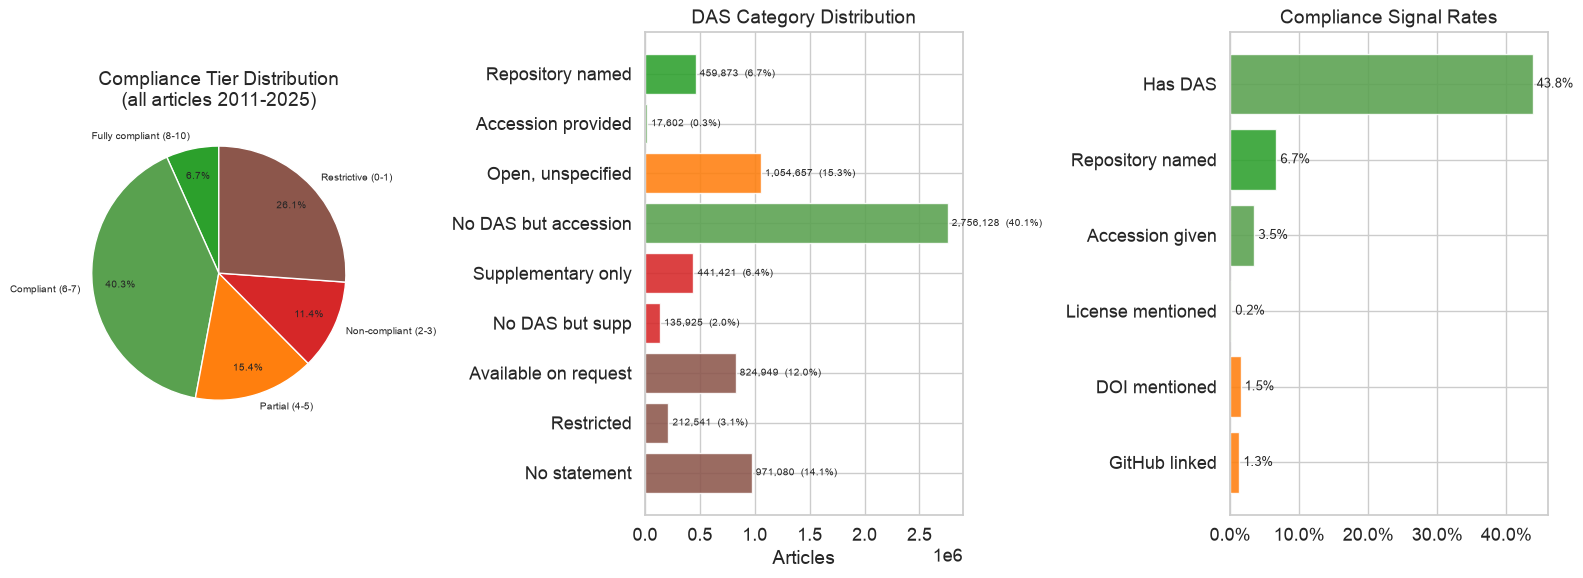

Overall compliance rate (score ≥ 6): 47.1%
Restrictive rate (score ≤ 1)          : 26.1%


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(FIG_W + 2, FIG_H + 1))

# (a) Compliance tier pie
ax = axes[0]
tier_vc = df['comply_tier'].value_counts().reindex(COMPLY_ORDER).dropna()
clrs_pie = COMPLY_CLRS[:len(tier_vc)]
_, txts, pcts = ax.pie(tier_vc.values,
    labels=[COMPLY_LABELS.get(t, t) for t in tier_vc.index],
    colors=clrs_pie, autopct='%1.1f%%', startangle=90, pctdistance=0.78)
for t in txts: t.set_fontsize(7.5)
for t in pcts: t.set_fontsize(7.5)
ax.set_title('Compliance Tier Distribution\n(all articles 2011-2025)')

# (b) DAS category bar
ax = axes[1]
CAT_ORDER  = ['repository_named','accession_provided','open_unspecified',
              'no_das_but_accession','supplementary_only','no_das_but_supp',
              'available_on_request','restricted','no_statement']
CAT_CLRS   = [C_FULL, C_COMPLY, C_PARTIAL, C_COMPLY, C_NON, C_NON, C_REST, C_REST, C_REST]
CAT_LABELS = {
    'repository_named':    'Repository named',
    'accession_provided':  'Accession provided',
    'open_unspecified':    'Open, unspecified',
    'no_das_but_accession':'No DAS but accession',
    'supplementary_only':  'Supplementary only',
    'no_das_but_supp':     'No DAS but supp',
    'available_on_request':'Available on request',
    'restricted':          'Restricted',
    'no_statement':        'No statement',
}
cat_vc = df['das_cat'].value_counts().reindex(CAT_ORDER).dropna()
bars = ax.barh([CAT_LABELS.get(c,c) for c in cat_vc.index][::-1],
               cat_vc.values[::-1],
               color=[CAT_CLRS[CAT_ORDER.index(c)] for c in cat_vc.index][::-1],
               alpha=0.88, edgecolor='white')
ax.bar_label(bars,
             labels=[f'{int(v):,}  ({v/len(df)*100:.1f}%)'
                     for v in cat_vc.values[::-1]],
             padding=3, fontsize=7.5)
ax.set_xlabel('Articles')
ax.set_title('DAS Category Distribution')

# (c) Key signals bar chart
ax = axes[2]
signals = {
    'Has DAS':         df['has_das'].mean()*100,
    'Repository named':  (df['das_cat']=='repository_named').mean()*100,
    'Accession given': df['has_accession'].mean()*100,
    'License mentioned': df['mentions_license'].mean()*100,
    'DOI mentioned':   df['mentions_doi'].mean()*100,
    'GitHub linked':   df['mentions_github'].mean()*100,
}
sig_clrs = [C_COMPLY, C_FULL, C_COMPLY, C_COMPLY, C_PARTIAL, C_PARTIAL]
bars2 = ax.barh(list(signals)[::-1], list(signals.values())[::-1],
                color=sig_clrs[::-1], alpha=0.88, edgecolor='white')
ax.bar_label(bars2, fmt='{:.1f}%', padding=3, fontsize=9)
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title('Compliance Signal Rates')

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_mandate_01_snapshot.png", **SAVEFIG_KWARGS)
plt.show()
pct_comply = df['is_compliant'].mean() * 100
print(f'Overall compliance rate (score ≥ 6): {pct_comply:.1f}%')
print(f'Restrictive rate (score ≤ 1)          : {(df["data_sharing_score"]<=1).mean()*100:.1f}%')


---
## §2 — Compliance Trend Over Time: Are Mandates Working?

The critical test: do compliance rates rise after major mandate milestones?
We mark four key inflection points:
- **2016** — FAIR principles published; Horizon 2020 ORD pilot
- **2017** — Wellcome/Gates/ERC strong enforcement
- **2019** — widespread journal DAS requirements
- **2023** — NIH DMS Policy fully enforced

In [ ]:
yr = (df.groupby('year').agg(
    n_total         = ('article_id','count'),
    pct_compliant   = ('is_compliant', lambda x: x.mean()*100),
    pct_full        = ('data_sharing_score', lambda x: (x>=8).mean()*100),
    pct_restrictive        = ('data_sharing_score', lambda x: (x<=1).mean()*100),
    mean_fair       = ('data_sharing_score', 'mean'),
    pct_has_das     = ('has_das', lambda x: x.mean()*100),
    pct_license     = ('mentions_license', lambda x: x.mean()*100),
    pct_doi_mention = ('mentions_doi', lambda x: x.mean()*100),
).reset_index())
yr = yr[yr['year'].between(2011, 2025)]

MANDATE_LINES = [
    (2016 - 0.33, '#4e79a7', '-',  'FAIR principles'),
    (2017 - 0.33, '#59a14f', '--', 'Wellcome/Gates/ERC enforcement'),
    (2019 - 0.33, '#f28e2b', ':',  'Journal mandate wave'),
    (2023 - 0.33, '#d62728', '-.', 'NIH DMS Policy'),
]

# Reviewer feedback on this figure (fig_mandate_02_trend.png): the in-figure
# legends overlapped the plotted series, and the third panel overlaid an
# absolute 0-10 score with two percentages manually rescaled by /10 onto a
# single axis, which reads as if they were on a shared 0-10 scale when
# they are not. Fixed by moving every legend outside its axes (so it can
# never sit over plotted data) and splitting that third panel into two:
# one panel for the absolute mean score, one for the two signals on their
# own natural 0-100% axis.
# Follow-up fix: the outside-axes legends sat to the right of each panel,
# which only works by giving the whole 4-panel row extra width (hence the
# "+ 6" below) -- at a fixed output size that extra width is taken directly
# out of each panel's actual plotting area, so the data itself renders
# smaller/lower-resolution than it needs to. Moved every legend below its
# panel instead (bbox_inches="tight" in SAVEFIG_KWARGS expands the saved
# canvas downward to fit it, so nothing is clipped), and shrunk the row back
# down since the panels no longer need to give up width to a side legend.
fig, axes = plt.subplots(1, 4, figsize=(FIG_W + 2, FIG_H + 1.3))

ax = axes[0]
ax.fill_between(yr['year'], yr['pct_compliant'], alpha=0.12, color=C_COMPLY)
ax.plot(yr['year'], yr['pct_compliant'], lw=2.5, marker='o', ms=5,
        color=C_COMPLY, label='Compliant (≥6)')
ax.fill_between(yr['year'], yr['pct_full'], alpha=0.12, color=C_FULL)
ax.plot(yr['year'], yr['pct_full'], lw=2.0, marker='s', ms=4,
        color=C_FULL, label='Fully compliant (8-10)', ls='--')
for x, c, ls, lbl in MANDATE_LINES:
    ax.axvline(x, color=c, lw=1.5, ls=ls, label=lbl)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title('Compliance Rate Over Time')
ax.set_xlabel('Year')
ax.legend(fontsize=6.5, loc='upper center', bbox_to_anchor=(0.5, -0.32),
          ncol=2, borderaxespad=0, frameon=False)

ax = axes[1]
ax.plot(yr['year'], yr['pct_restrictive'], lw=2.5, marker='o', ms=5,
        color=C_REST, label='Restrictive (score ≤1)')
ax.fill_between(yr['year'], yr['pct_restrictive'], alpha=0.12, color=C_REST)
for x, c, ls, _ in MANDATE_LINES:
    ax.axvline(x, color=c, lw=1.5, ls=ls)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title('Restrictive Rate Over Time\n("Available on request" + no statement)')
ax.set_xlabel('Year')

ax = axes[2]
ax.plot(yr['year'], yr['mean_fair'], lw=2.5, marker='D', ms=5,
        color='#6c3483', label='Mean data-sharing score')
for x, c, ls, _ in MANDATE_LINES:
    ax.axvline(x, color=c, lw=1.5, ls=ls)
ax.set_ylabel('Mean data-sharing score (0-10)')
ax.set_title('Mean Data-Sharing Score Over Time')
ax.set_xlabel('Year')
ax.legend(fontsize=7, loc='upper center', bbox_to_anchor=(0.5, -0.22),
          borderaxespad=0, frameon=False)

ax = axes[3]
ax.plot(yr['year'], yr['pct_has_das'], lw=1.8, marker='o', ms=4,
        color=C_PRE, ls='--', label='DAS presence')
ax.plot(yr['year'], yr['pct_license'], lw=1.8, marker='s', ms=4,
        color=C_COMPLY, ls=':', label='License mention')
for x, c, ls, _ in MANDATE_LINES:
    ax.axvline(x, color=c, lw=1.5, ls=ls)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title('Key Signal Prevalence Over Time')
ax.set_xlabel('Year')
ax.legend(fontsize=7, loc='upper center', bbox_to_anchor=(0.5, -0.22),
          borderaxespad=0, frameon=False)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_mandate_02_trend.png", **SAVEFIG_KWARGS)
plt.show()

# Print the stacked compliance tier by year
yr_tier = (df.groupby(['year','comply_tier']).size()
           .unstack(fill_value=0).reindex(columns=COMPLY_ORDER, fill_value=0))
yr_tier_pct = yr_tier.div(yr_tier.sum(axis=1), axis=0) * 100
print('\nCompliance tier % by year:')
print(yr_tier_pct.round(1).to_string())

---
## §3 — Funder Compliance Deep-Dive

Comparing compliance rates across the major funding agencies with known
data-sharing mandates. Agencies with stronger or earlier mandates should
show higher compliance rates and lower restrictive rates.

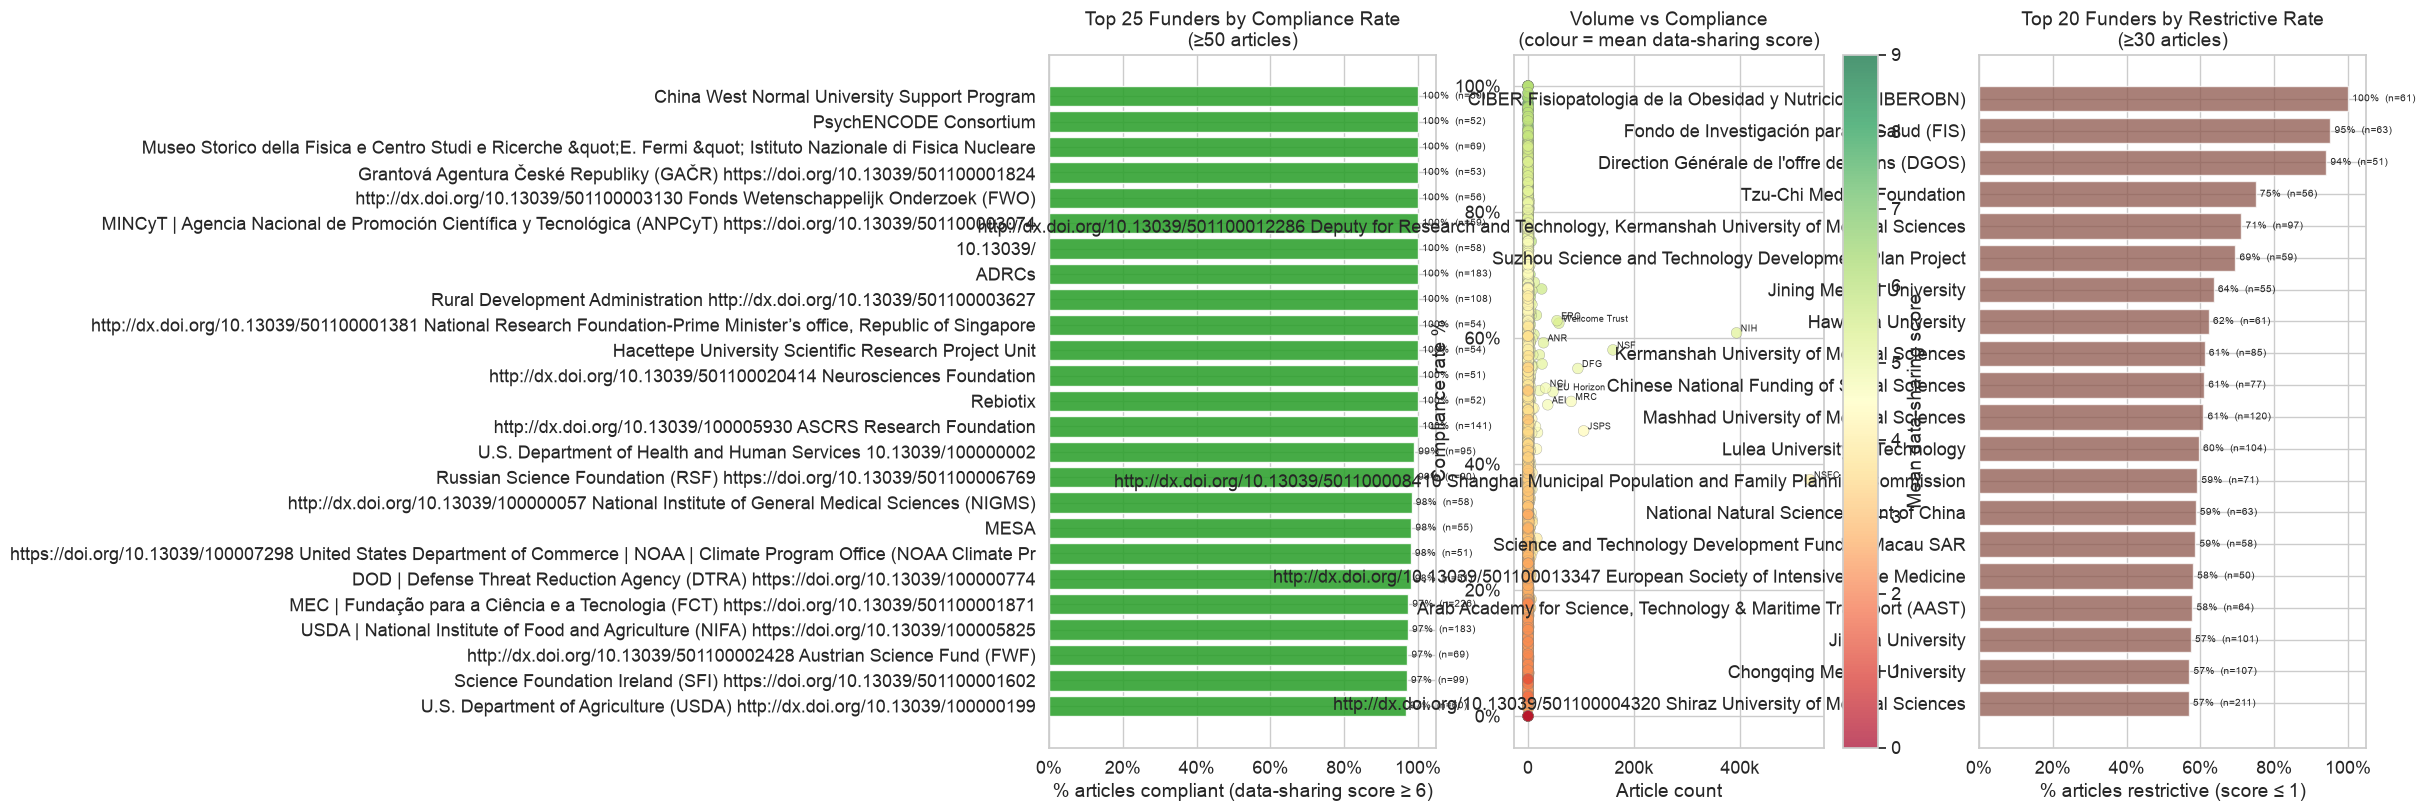

                                                                                                                  funder   n country  pct_comply  mean_fair  pct_restrictive  pct_full
                                                                            China West Normal University Support Program  50     NaN       100.0        9.0              0.0     100.0
                                                                                                                    MESA  55     NaN        98.2        8.2              0.0      89.1
                                                                                                  PsychENCODE Consortium  52     NaN       100.0        8.0              0.0     100.0
        Museo Storico della Fisica e Centro Studi e Ricerche &quot;E. Fermi &quot; Istituto Nazionale di Fisica Nucleare  69     NaN       100.0        8.0              0.0     100.0
https://doi.org/10.13039/100007298 United States Department of Commerce | NOAA | Clim

In [6]:
if not HAS_FUNDER:
    print('Skipped — funder data not available in this database.')
else:
    df_af = qdb("""
        SELECT af.article_id, af.funder_norm AS funder,
               af.funder_country AS country,
               a.year AS year
        FROM article_funder af
        JOIN article a ON a.article_id = af.article_id
        WHERE af.funder_norm != 'none'
          AND a.year BETWEEN 2011 AND 2025
    """)
    df_af = df_af.merge(df[['article_id','data_sharing_score','is_compliant',
                             'comply_tier','das_cat','mentions_license',
                             'has_accession','era']], on='article_id', how='left')

    # Aggregate per funder
    f_agg = (df_af.groupby('funder').agg(
        n            = ('article_id',     'count'),
        country      = ('country',        'first'),
        pct_comply   = ('is_compliant',   lambda x: x.mean()*100),
        mean_fair    = ('data_sharing_score',      'mean'),
        pct_restrictive     = ('data_sharing_score',      lambda x: (x<=1).mean()*100),
        pct_full     = ('data_sharing_score',      lambda x: (x>=8).mean()*100),
        pct_repo     = ('das_cat',         lambda x: (x=='repository_named').mean()*100),
        pct_license  = ('mentions_license',lambda x: x.mean()*100),
        pct_acc      = ('has_accession',   lambda x: x.mean()*100),
    ).reset_index())
    f_agg_50 = f_agg[f_agg['n'] >= 50].sort_values('mean_fair', ascending=False)

    # Add mandate metadata where available
    def get_mandate_tier(funder):
        for key, meta in FUNDER_MANDATES.items():
            if key.lower() in str(funder).lower():
                return meta['tier'], meta['mandate_year']
        return 'unknown', None
    f_agg_50[['mandate_tier','mandate_year']] = pd.DataFrame(
        f_agg_50['funder'].apply(get_mandate_tier).tolist(),
        index=f_agg_50.index)

    fig, axes = plt.subplots(1, 3, figsize=(FIG_W + 3, FIG_H + 4))

    # (a) Top 25 by compliance rate
    ax = axes[0]
    top25 = f_agg_50.nlargest(25, 'pct_comply')
    clrs_f = [C_FULL if r >= 70 else (C_COMPLY if r >= 50 else C_PARTIAL)
              for r in top25['pct_comply'][::-1]]
    bars = ax.barh(top25['funder'][::-1], top25['pct_comply'][::-1],
                   color=clrs_f, alpha=0.88, edgecolor='white')
    ax.bar_label(bars, labels=[f'{r:.0f}%  (n={int(n):,})'
                 for r, n in zip(top25['pct_comply'][::-1], top25['n'][::-1])],
                 padding=3, fontsize=7)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(xmax=100))
    ax.set_xlabel('% articles compliant (data-sharing score ≥ 6)')
    ax.set_title('Top 25 Funders by Compliance Rate\n(≥50 articles)')

    # (b) Volume vs compliance scatter coloured by mean data-sharing score
    ax = axes[1]
    plot_f = f_agg_50.dropna(subset=['pct_comply','mean_fair'])
    sc = ax.scatter(plot_f['n'], plot_f['pct_comply'],
                    c=plot_f['mean_fair'], cmap='RdYlGn',
                    s=60, alpha=0.7, edgecolors='grey', lw=0.3)
    plt.colorbar(sc, ax=ax, label='Mean data-sharing score')
    for _, row in plot_f.nlargest(12,'n').iterrows():
        ax.annotate(str(row['funder'])[:20],
                    (row['n'], row['pct_comply']),
                    fontsize=6.5, xytext=(3,1), textcoords='offset points')
    ax.xaxis.set_major_formatter(
        mtick.FuncFormatter(lambda v,_: f'{v/1000:.0f}k' if v>=1000 else str(int(v))))
    ax.yaxis.set_major_formatter(mtick.PercentFormatter())
    ax.set_xlabel('Article count')
    ax.set_ylabel('Compliance rate %')
    ax.set_title('Volume vs Compliance\n(colour = mean data-sharing score)')

    # (c) Bottom 25 by restrictive rate (worst offenders)
    ax = axes[2]
    bot25 = f_agg_50[f_agg_50['n'] >= 30].nlargest(20, 'pct_restrictive')
    bars2 = ax.barh(bot25['funder'][::-1], bot25['pct_restrictive'][::-1],
                    color=C_REST, alpha=0.75, edgecolor='white')
    ax.bar_label(bars2, labels=[f'{r:.0f}%  (n={int(n):,})'
                 for r, n in zip(bot25['pct_restrictive'][::-1], bot25['n'][::-1])],
                 padding=3, fontsize=7)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(xmax=100))
    ax.set_xlabel('% articles restrictive (score ≤ 1)')
    ax.set_title('Top 20 Funders by Restrictive Rate\n(≥30 articles)')

    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "fig_mandate_03_funders.png", **SAVEFIG_KWARGS)
    plt.show()
    print(f_agg_50[['funder','n','country','pct_comply','mean_fair',
                     'pct_restrictive','pct_full']].head(20).round(1).to_string(index=False))


---
## §4 — Funder Pre/Post Mandate Delta

Did specific policy changes actually move the needle? We measure each
funder's data-sharing score before and after their mandate year, computing the
delta and testing statistical significance. A large positive delta for
high-mandate funders — with little change for low-mandate ones — is
the causal signature we are looking for.

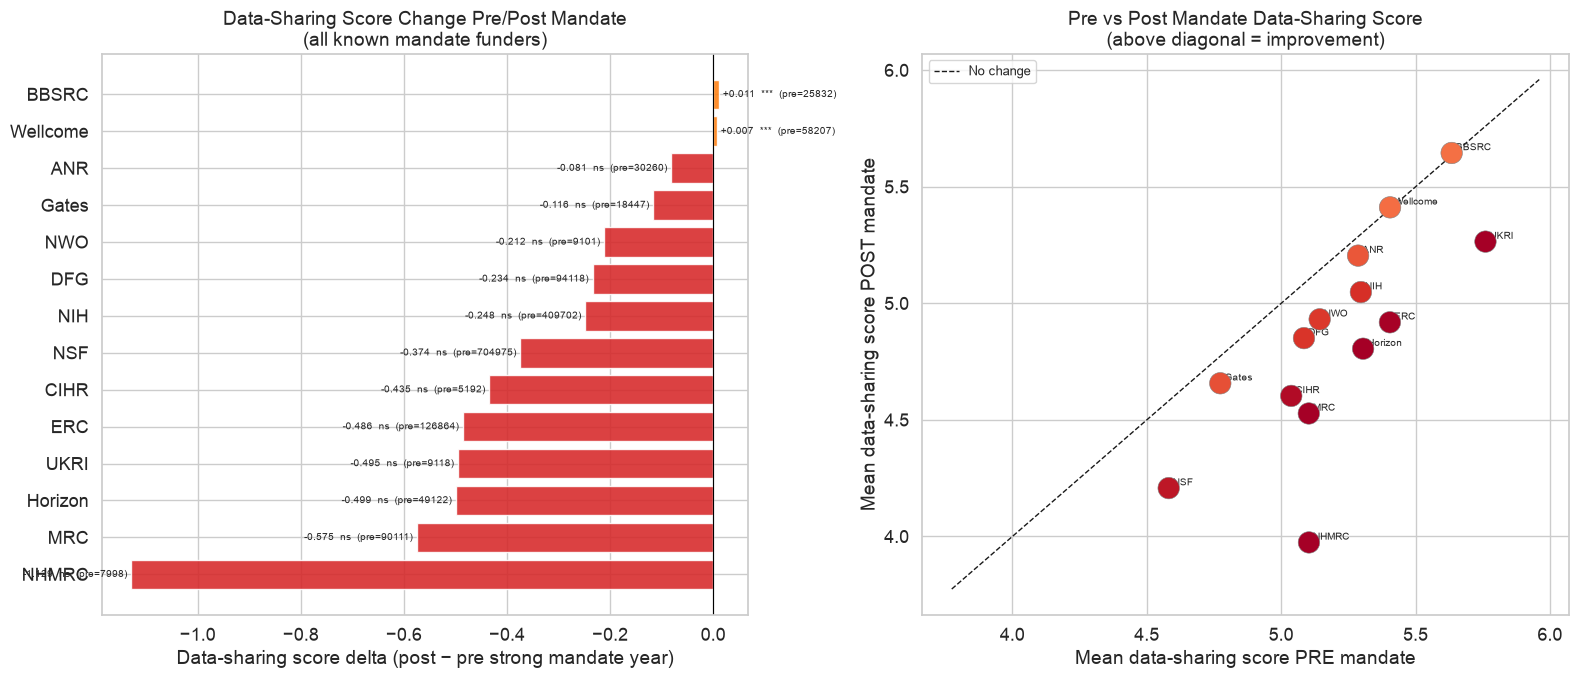

  funder  strong_year  n_pre  n_post  mean_pre  mean_post  delta sig
   BBSRC         2018   5495   20337     5.634      5.645  0.011 ***
Wellcome         2017   8966   49241     5.405      5.412  0.007 ***
     ANR         2021  11395   18865     5.286      5.205 -0.081  ns
   Gates         2017   1908   16539     4.774      4.657 -0.116  ns
     NWO         2020   3663    5438     5.143      4.932 -0.212  ns
     DFG         2022  41492   52626     5.085      4.851 -0.234  ns
     NIH         2023 232788  176914     5.297      5.048 -0.248  ns
     NSF         2023 362048  342927     4.582      4.207 -0.374  ns
    CIHR         2020   1143    4049     5.038      4.603 -0.435  ns
     ERC         2017   8520  118344     5.405      4.919 -0.486  ns
    UKRI         2022   1647    7471     5.760      5.265 -0.495  ns
 Horizon         2017   5548   43574     5.305      4.806 -0.499  ns
     MRC         2018  19543   70568     5.103      4.528 -0.575  ns
   NHMRC         2020   4117    38

In [7]:
if not HAS_FUNDER:
    print('Skipped — no funder data.')
else:
    # For each funder in FUNDER_MANDATES, compute pre/post the *strong* enforcement year
    mandate_rows = []
    for funder_key, meta in FUNDER_MANDATES.items():
        strong_yr = meta['strong_year']
        # Match articles by funder name
        mask = df_af['funder'].str.contains(funder_key, case=False, na=False)
        sub  = df_af[mask]  # already has data_sharing_score from the merge in the previous cell
        if len(sub) < 20: continue
        pre  = sub[sub['year'] < strong_yr]['data_sharing_score'].dropna()
        post = sub[sub['year'] >= strong_yr]['data_sharing_score'].dropna()
        if len(pre) < 5 or len(post) < 5: continue
        u, p = stats.mannwhitneyu(post, pre, alternative='greater')
        mandate_rows.append({
            'funder':        funder_key,
            'country':       meta['country'],
            'strong_year':   strong_yr,
            'policy':        meta['policy'],
            'n_pre':         len(pre),
            'n_post':        len(post),
            'mean_pre':      pre.mean(),
            'mean_post':     post.mean(),
            'delta':         post.mean() - pre.mean(),
            'p_value':       p,
            'sig':           '***' if p<0.001 else ('**' if p<0.01 else ('*' if p<0.05 else 'ns')),
        })
    df_mandate = pd.DataFrame(mandate_rows).sort_values('delta', ascending=False)

    fig, axes = plt.subplots(1, 2, figsize=(FIG_W + 2, FIG_H + 2))

    ax = axes[0]
    clrs_delta = [C_FULL if d >= 1.0 else (C_COMPLY if d >= 0.3 else
                  (C_PARTIAL if d >= 0 else C_NON))
                  for d in df_mandate['delta'][::-1]]
    bars = ax.barh(df_mandate['funder'][::-1], df_mandate['delta'][::-1],
                   color=clrs_delta, alpha=0.88, edgecolor='white')
    ax.bar_label(bars,
                 labels=[f'{d:+.3f}  {s}  (pre={int(np)+int(ns)})'
                         for d, s, np, ns in zip(
                             df_mandate['delta'][::-1], df_mandate['sig'][::-1],
                             df_mandate['n_pre'][::-1], df_mandate['n_post'][::-1])],
                 padding=3, fontsize=7.5)
    ax.axvline(0, color='black', lw=0.8)
    ax.set_xlabel('Data-sharing score delta (post − pre strong mandate year)')
    ax.set_title('Data-Sharing Score Change Pre/Post Mandate\n(all known mandate funders)')

    ax = axes[1]
    if len(df_mandate) >= 2:
        ax.scatter(df_mandate['mean_pre'], df_mandate['mean_post'],
                   s=df_mandate['n_pre'].clip(upper=1000)/5 + 40,
                   c=df_mandate['delta'], cmap='RdYlGn',
                   edgecolors='grey', lw=0.4, zorder=5, vmin=-0.5, vmax=2)
        for _, row in df_mandate.iterrows():
            ax.annotate(row['funder'],
                        (row['mean_pre'], row['mean_post']),
                        fontsize=7, xytext=(3,2), textcoords='offset points')
        mn = min(df_mandate['mean_pre'].min(), df_mandate['mean_post'].min()) - 0.2
        mx = max(df_mandate['mean_pre'].max(), df_mandate['mean_post'].max()) + 0.2
        ax.plot([mn,mx], [mn,mx], 'k--', lw=1, label='No change')
        ax.set_xlabel('Mean data-sharing score PRE mandate')
        ax.set_ylabel('Mean data-sharing score POST mandate')
        ax.set_title('Pre vs Post Mandate Data-Sharing Score\n(above diagonal = improvement)')
        ax.legend(fontsize=9)

    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "fig_mandate_04_delta.png", **SAVEFIG_KWARGS)
    plt.show()
    print(df_mandate[['funder','strong_year','n_pre','n_post','mean_pre',
                       'mean_post','delta','sig']].round(3).to_string(index=False))


---
## §5 — Funder Compliance Trend: Top 8 Funders Over Time

Year-by-year data-sharing score trajectories for the eight highest-volume funders,
with each funder's mandate year annotated. We can see whether the trajectory
bends upward at the mandate year — the 'policy bend' test.

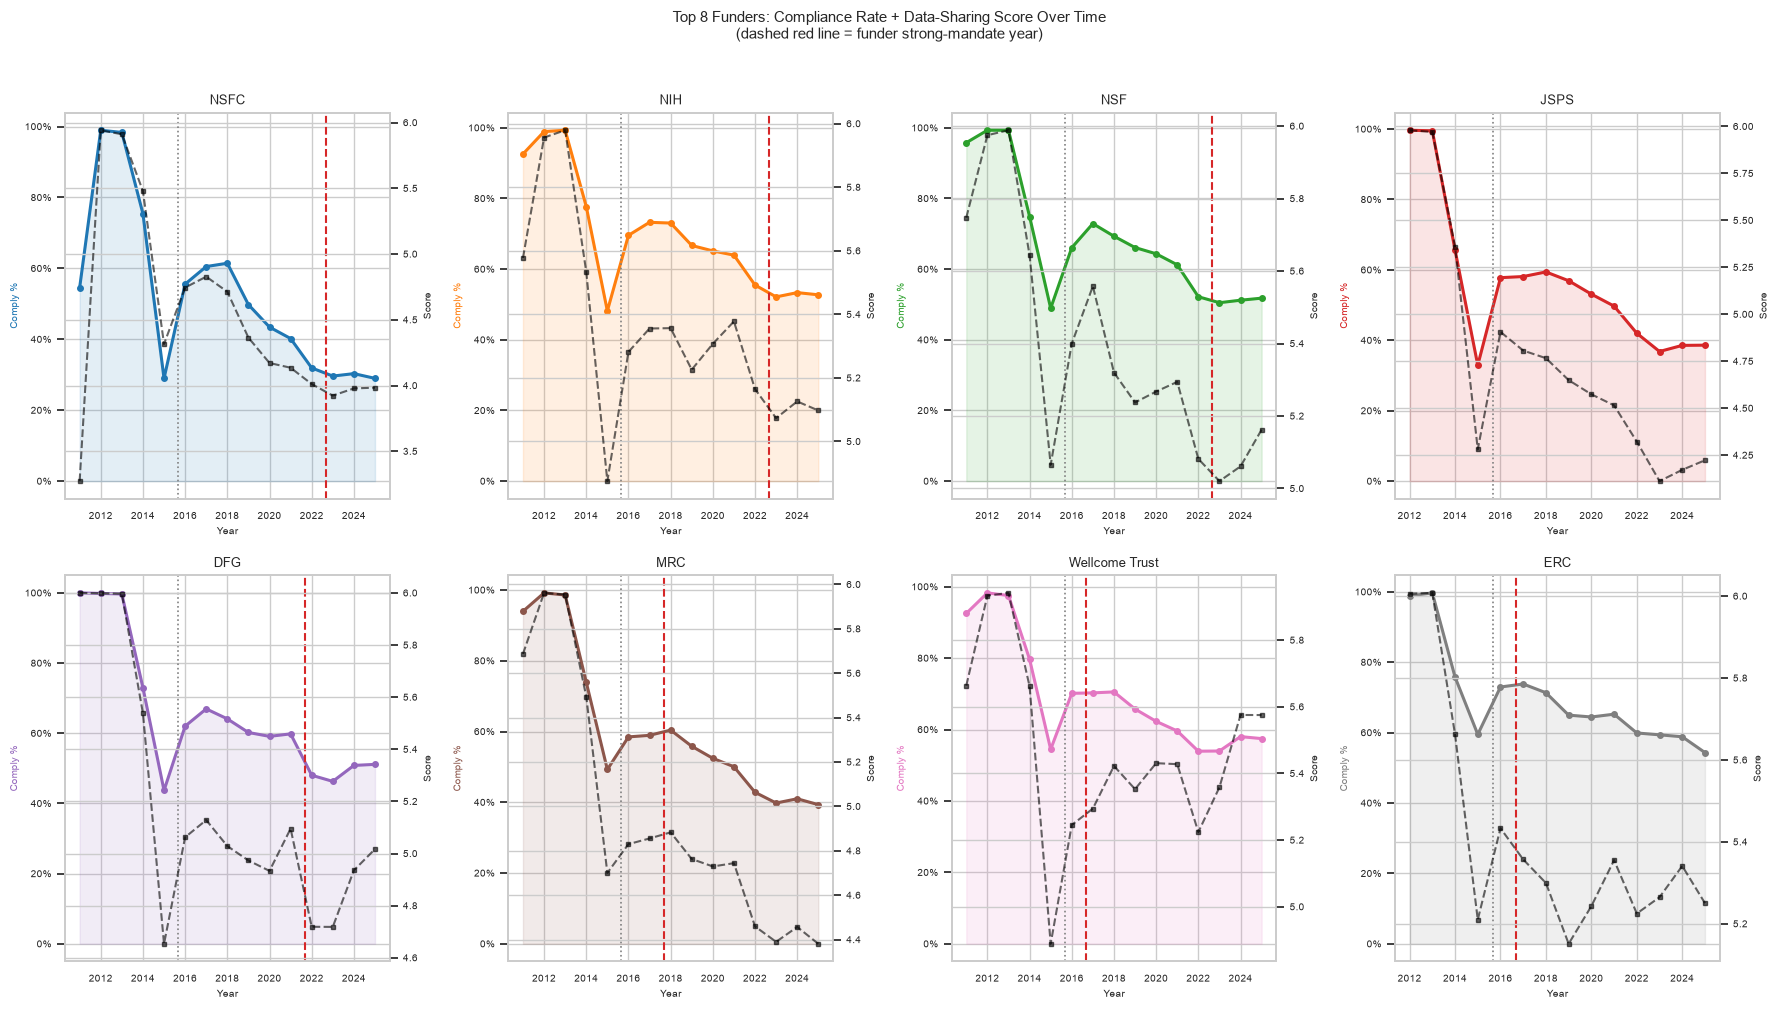

In [8]:
if not HAS_FUNDER:
    print('Skipped — no funder data.')
else:
    # Year-by-year per funder (df_af already has data_sharing_score/is_compliant from
    # its earlier merge, so this is computed directly in pandas, not SQL)
    f_yr2 = (df_af.groupby(['funder','year']).agg(
        mean_fair  = ('data_sharing_score',    'mean'),
        n          = ('article_id',    'count'),
        pct_comply = ('is_compliant',  lambda x: x.mean()*100),
    ).reset_index())
    f_yr2 = f_yr2[f_yr2['n'] >= 5]

    top8 = (df_af.groupby('funder')['article_id'].count()
            .nlargest(8).index.tolist())
    f_yr_top = f_yr2[f_yr2['funder'].isin(top8)]

    fig, axes = plt.subplots(2, 4, figsize=(FIG_W + 4, FIG_H * 2))
    axes = axes.flatten()
    pal = plt.cm.tab10(np.linspace(0,1,10))

    for i, funder in enumerate(top8):
        ax = axes[i]
        sub = f_yr_top[f_yr_top['funder']==funder].sort_values('year')
        ax.fill_between(sub['year'], sub['pct_comply'], alpha=0.12, color=pal[i])
        ax.plot(sub['year'], sub['pct_comply'], lw=2.2, marker='o', ms=4,
                color=pal[i], label='Comply %')
        ax2r = ax.twinx()
        ax2r.plot(sub['year'], sub['mean_fair'], lw=1.5, marker='s', ms=3,
                  color='black', ls='--', alpha=0.6, label='Mean score')
        ax.axvline(FAIR_YEAR - 0.33, color='grey', lw=1.2, ls=':')
        # Add mandate year line if known
        for key, meta in FUNDER_MANDATES.items():
            if key.lower() in funder.lower():
                ax.axvline(meta['strong_year'] - 0.33, color=C_NON, lw=1.5, ls='--')
                break
        ax.yaxis.set_major_formatter(mtick.PercentFormatter())
        ax.set_title(f'{str(funder)[:22]}', fontsize=9)
        ax.set_xlabel('Year', fontsize=7.5)
        ax.set_ylabel('Comply %', fontsize=7, color=pal[i])
        ax2r.set_ylabel('Score', fontsize=7)
        ax.tick_params(axis='both', labelsize=7)
        ax2r.tick_params(axis='y', labelsize=7)

    for j in range(len(top8), len(axes)):
        axes[j].set_visible(False)

    plt.suptitle('Top 8 Funders: Compliance Rate + Data-Sharing Score Over Time\n'
                 '(dashed red line = funder strong-mandate year)',
                 fontsize=11, y=1.01)
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "fig_mandate_05_funder_trend.png", **SAVEFIG_KWARGS)
    plt.show()


---
## §6 — Journal-Level Compliance

Journals with explicit DAS requirements should have higher compliance rates
than those with recommended-only or no policies. We rank journals by compliance
rate, examine the correlation between journal size and compliance, and identify
outliers — large journals with low compliance or small journals with high compliance.

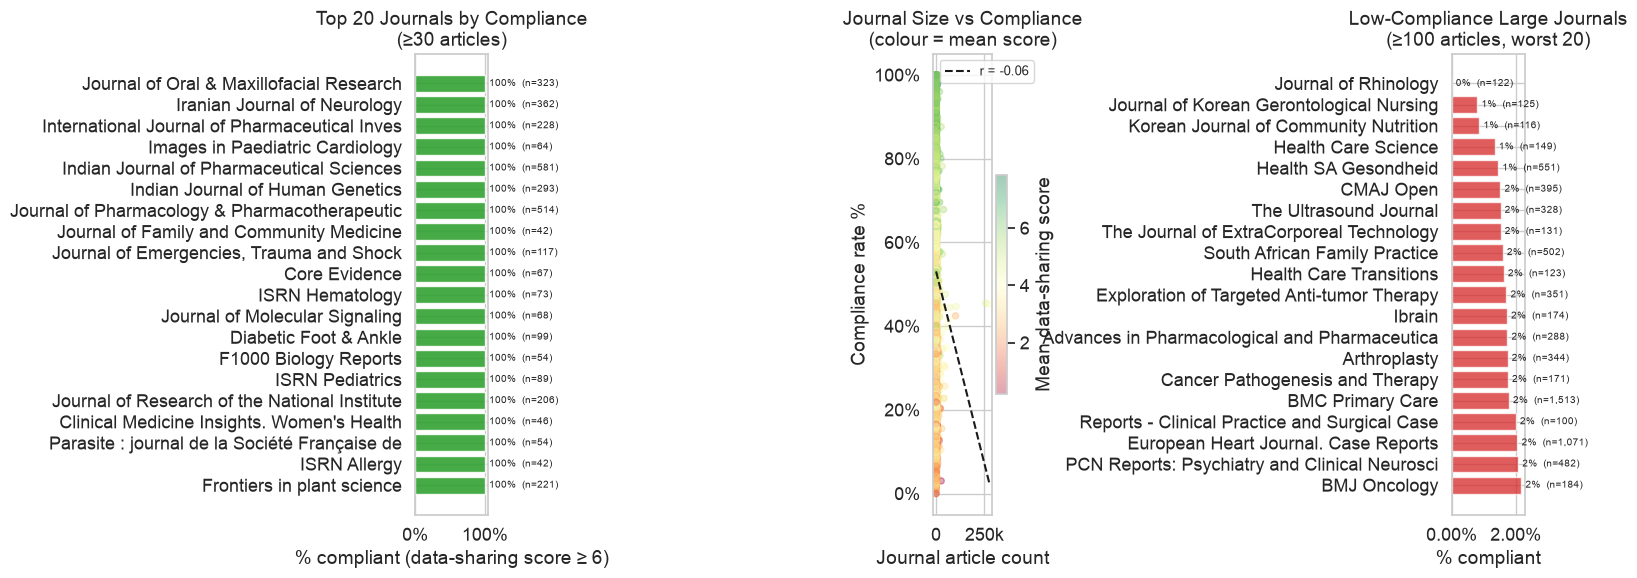

Journals ≥30 articles: 3623
Mean compliance rate : 52.8%


In [9]:
# Journal aggregation
j_agg = (df.groupby(['journal_id','journal_title','publisher']).agg(
    n_total      = ('article_id', 'count'),
    pct_comply   = ('is_compliant', lambda x: x.mean()*100),
    pct_full     = ('data_sharing_score', lambda x: (x>=8).mean()*100),
    pct_restrictive     = ('data_sharing_score', lambda x: (x<=1).mean()*100),
    mean_fair    = ('data_sharing_score', 'mean'),
    pct_has_das  = ('has_das', lambda x: x.mean()*100),
    pct_license  = ('mentions_license', lambda x: x.mean()*100),
).reset_index())
j30 = j_agg[j_agg['n_total'] >= 30].copy()
j30['jtitle_short'] = j30['journal_title'].apply(lambda t: str(t or '')[:45])

fig, axes = plt.subplots(1, 3, figsize=(FIG_W + 2, FIG_H + 1))

# (a) Top 20 journals by compliance rate
ax = axes[0]
top20 = j30.nlargest(20, 'pct_comply')
clrs_j = [C_FULL if r>=80 else (C_COMPLY if r>=60 else C_PARTIAL)
          for r in top20['pct_comply'][::-1]]
bars = ax.barh(top20['jtitle_short'][::-1], top20['pct_comply'][::-1],
               color=clrs_j, alpha=0.88, edgecolor='white')
ax.bar_label(bars, labels=[f'{r:.0f}%  (n={int(n):,})'
             for r, n in zip(top20['pct_comply'][::-1], top20['n_total'][::-1])],
             padding=3, fontsize=7)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(xmax=100))
ax.set_xlabel('% compliant (data-sharing score ≥ 6)')
ax.set_title('Top 20 Journals by Compliance\n(≥30 articles)')

# (b) Scatter: journal size vs compliance rate
ax = axes[1]
sc = ax.scatter(j30['n_total'], j30['pct_comply'],
                alpha=0.35, s=20, c=j30['mean_fair'], cmap='RdYlGn')
plt.colorbar(sc, ax=ax, label='Mean data-sharing score')
if len(j30) >= 5:
    sl, ic, r, _, _ = stats.linregress(j30['n_total'].fillna(0),
                                        j30['pct_comply'].fillna(0))
    xs = np.linspace(30, j30['n_total'].max(), 100)
    ax.plot(xs, ic+sl*xs, 'k--', lw=1.5, label=f'r = {r:.2f}')
    ax.legend(fontsize=9)
ax.xaxis.set_major_formatter(
    mtick.FuncFormatter(lambda v,_: f'{v/1000:.0f}k' if v>=1000 else str(int(v))))
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_xlabel('Journal article count')
ax.set_ylabel('Compliance rate %')
ax.set_title('Journal Size vs Compliance\n(colour = mean score)')

# (c) Bottom 20 journals by compliance (large journals that lag)
ax = axes[2]
bot20 = j30[j30['n_total']>=100].nsmallest(20,'pct_comply')
bars2 = ax.barh(bot20['jtitle_short'][::-1], bot20['pct_comply'][::-1],
                color=C_NON, alpha=0.75, edgecolor='white')
ax.bar_label(bars2, labels=[f'{r:.0f}%  (n={int(n):,})'
             for r, n in zip(bot20['pct_comply'][::-1], bot20['n_total'][::-1])],
             padding=3, fontsize=7)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(xmax=100))
ax.set_xlabel('% compliant')
ax.set_title('Low-Compliance Large Journals\n(≥100 articles, worst 20)')

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_mandate_06_journals.png", **SAVEFIG_KWARGS)
plt.show()
print(f'Journals ≥30 articles: {len(j30)}')
print(f'Mean compliance rate : {j30["pct_comply"].mean():.1f}%')


---
## §7 — Publisher Compliance Ranking

Publishers set and enforce journal DAS policies at scale. A publisher with
strong across-the-board policies should show higher compliance than one with
inconsistent or optional policies. We rank the top 30 publishers by compliance
rate and show the restrictive rate alongside.

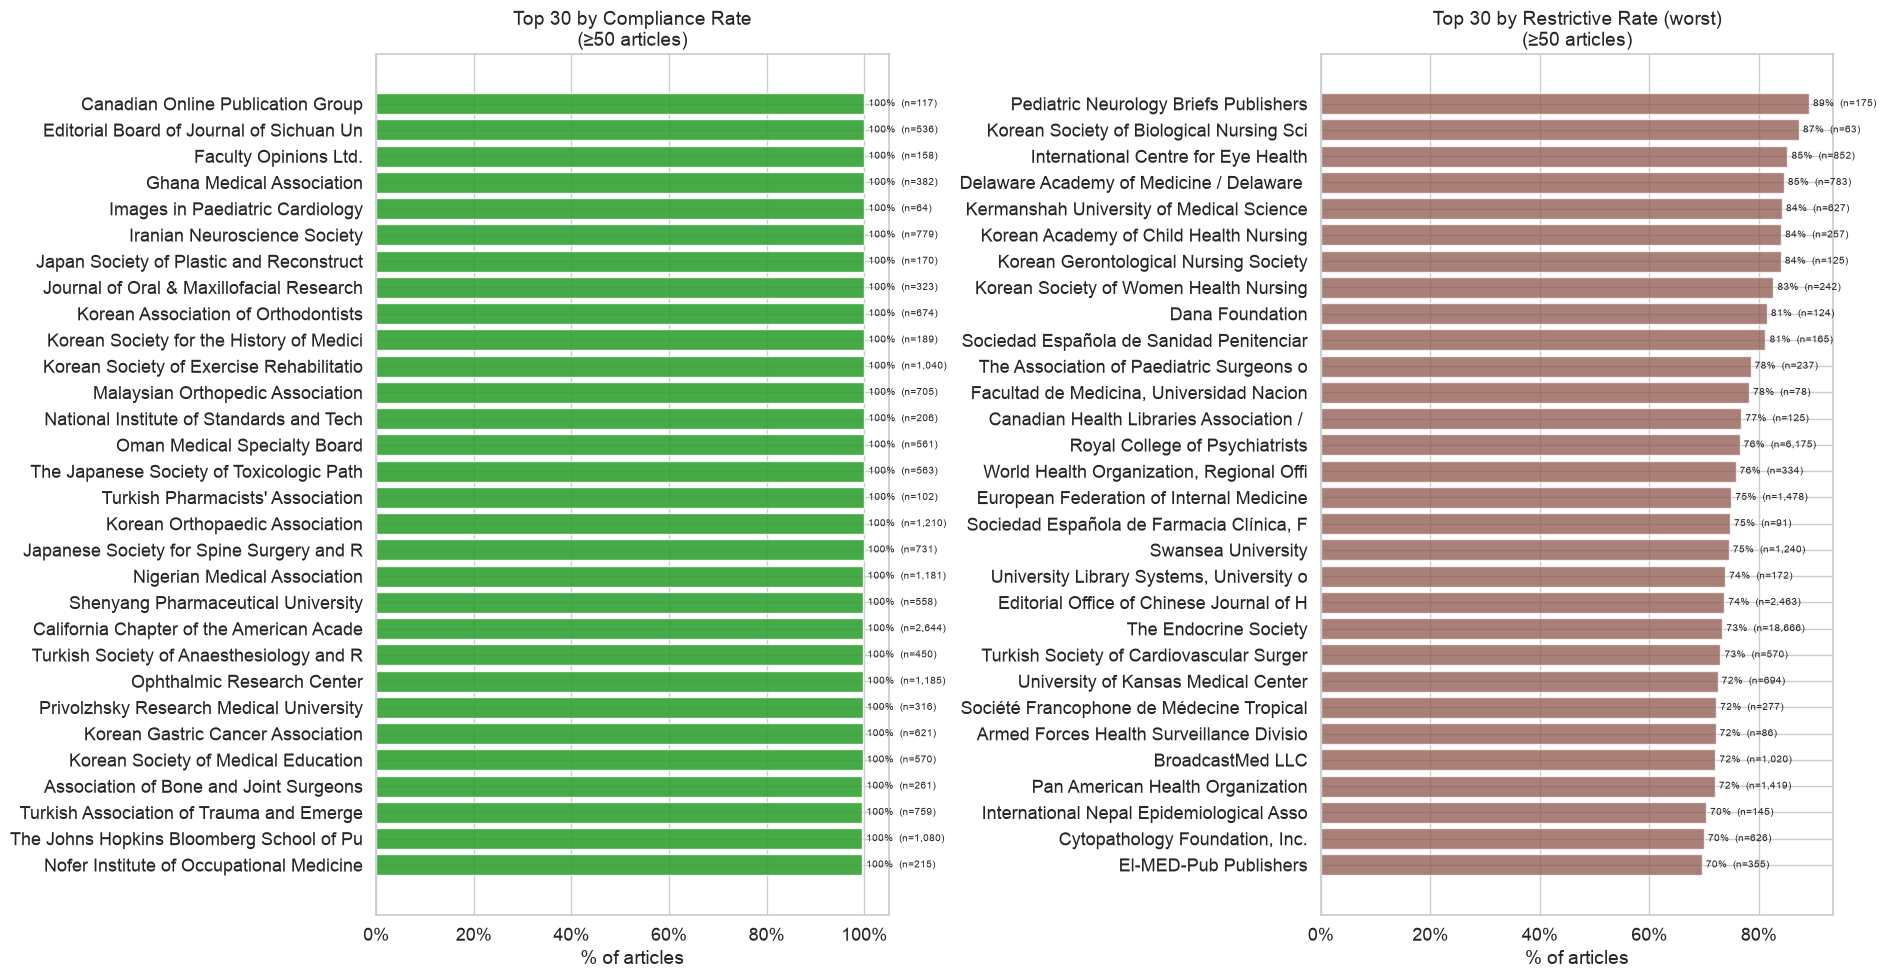

                               pub_short  n_total  pct_comply  mean_fair  pct_restrictive
       Canadian Online Publication Group      117       100.0        6.0              0.0
Editorial Board of Journal of Sichuan Un      536       100.0        6.0              0.0
                   Faculty Opinions Ltd.      158       100.0        6.0              0.0
               Ghana Medical Association      382       100.0        6.0              0.0
         Images in Paediatric Cardiology       64       100.0        6.0              0.0
            Iranian Neuroscience Society      779       100.0        6.0              0.0
Japan Society of Plastic and Reconstruct      170       100.0        6.0              0.0
Journal of Oral & Maxillofacial Research      323       100.0        6.0              0.0
     Korean Association of Orthodontists      674       100.0        6.0              0.0
Korean Society for the History of Medici      189       100.0        6.0              0.0
Korean Soc

In [10]:
pub_agg = (df.groupby('publisher').agg(
    n_total    = ('article_id', 'count'),
    pct_comply = ('is_compliant', lambda x: x.mean()*100),
    pct_full   = ('data_sharing_score', lambda x: (x>=8).mean()*100),
    pct_restrictive   = ('data_sharing_score', lambda x: (x<=1).mean()*100),
    mean_fair  = ('data_sharing_score', 'mean'),
).reset_index())
pub_50 = pub_agg[pub_agg['n_total'] >= 50].copy()
pub_50['pub_short'] = pub_50['publisher'].apply(lambda p: str(p or '(unknown)')[:40])

fig, axes = plt.subplots(1, 2, figsize=(FIG_W + 5, FIG_H + 5))

for ax, sort_col, clr, title in [
        (axes[0], 'pct_comply', None, 'Top 30 by Compliance Rate'),
        (axes[1], 'pct_restrictive',   C_REST, 'Top 30 by Restrictive Rate (worst)')]:
    if sort_col == 'pct_comply':
        sub = pub_50.nlargest(30, sort_col)
        bar_clrs = [C_FULL if r>=70 else (C_COMPLY if r>=50 else C_PARTIAL)
                    for r in sub['pct_comply'][::-1]]
        bars = ax.barh(sub['pub_short'][::-1], sub[sort_col][::-1],
                       color=bar_clrs, alpha=0.88, edgecolor='white')
    else:
        sub = pub_50.nlargest(30, sort_col)
        bars = ax.barh(sub['pub_short'][::-1], sub[sort_col][::-1],
                       color=clr, alpha=0.75, edgecolor='white')
    ax.bar_label(bars,
                 labels=[f'{v:.0f}%  (n={int(n):,})'
                         for v, n in zip(sub[sort_col][::-1], sub['n_total'][::-1])],
                 padding=3, fontsize=7)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(xmax=100))
    ax.set_xlabel('% of articles')
    ax.set_title(title + '\n(≥50 articles)')

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_mandate_07_publishers.png", **SAVEFIG_KWARGS)
plt.show()
print(pub_50.nlargest(20,'pct_comply')[['pub_short','n_total','pct_comply',
                                         'mean_fair','pct_restrictive']].round(1).to_string(index=False))


---
## §8 — Restrictive-Sharing Spotlight: 'Available on Request'

'Available on request' is the most explicit form of non-compliance:
the author acknowledges they have data but refuses to share it proactively.
This practice is banned by PLOS journals and discouraged by NIH.
We trace its prevalence over time, by funder, and by discipline.

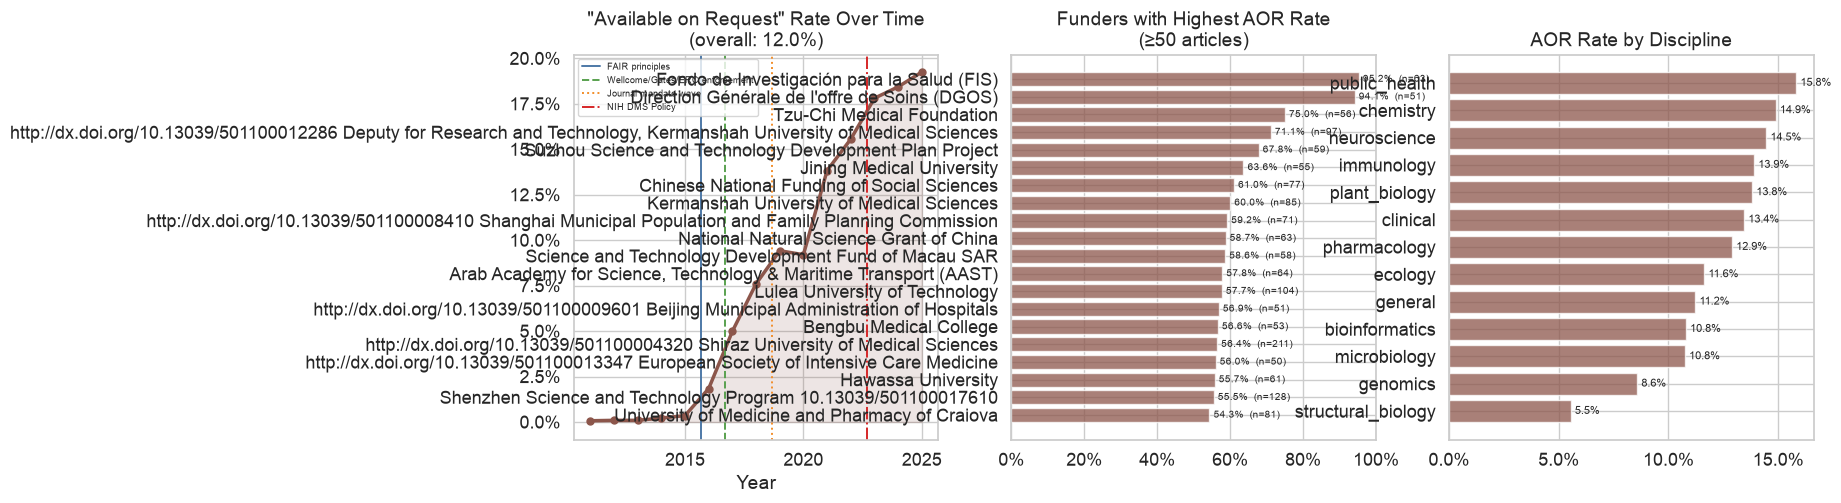

Total "available on request" articles: 824,949 (12.0%)


In [11]:
df_aor = df[df['das_cat'] == 'available_on_request'].copy()
n_aor  = len(df_aor)
pct_aor = n_aor / len(df) * 100

df['is_aor'] = df['das_cat'] == 'available_on_request'
aor_yr = (df.groupby('year')['is_aor'].mean() * 100).reset_index(name='pct_aor')

fig, axes = plt.subplots(1, 3, figsize=(FIG_W + 2, FIG_H))

ax = axes[0]
ax.fill_between(aor_yr['year'], aor_yr['pct_aor'], alpha=0.15, color=C_REST)
ax.plot(aor_yr['year'], aor_yr['pct_aor'], lw=2.5, marker='o', ms=5, color=C_REST)
for x, c, ls, lbl in MANDATE_LINES:
    ax.axvline(x, color=c, lw=1.4, ls=ls, label=lbl)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title(f'"Available on Request" Rate Over Time\n(overall: {pct_aor:.1f}%)')
ax.set_xlabel('Year'); ax.legend(fontsize=6.5)

ax = axes[1]
if HAS_FUNDER:
    # df_af already has das_cat from its merge in the earlier cell -- no need
    # to re-merge (doing so would collide and suffix both copies as _x/_y)
    df_af['is_aor'] = df_af['das_cat'] == 'available_on_request'
    aor_f = (df_af.groupby('funder')['is_aor'].mean() * 100).reset_index(name='pct_aor')
    aor_f = aor_f.merge(df_af.groupby('funder')['article_id'].count()
                        .reset_index(name='n'), on='funder')
    aor_f_50 = aor_f[aor_f['n'] >= 50].nlargest(20,'pct_aor')
    bars = ax.barh(aor_f_50['funder'][::-1], aor_f_50['pct_aor'][::-1],
                   color=C_REST, alpha=0.75, edgecolor='white')
    ax.bar_label(bars, labels=[f'{r:.1f}%  (n={int(n):,})'
                 for r, n in zip(aor_f_50['pct_aor'][::-1], aor_f_50['n'][::-1])],
                 padding=3, fontsize=7.5)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(xmax=100))
    ax.set_title('Funders with Highest AOR Rate\n(≥50 articles)')
else:
    ax.text(0.5, 0.5, 'No funder data', ha='center', va='center',
            transform=ax.transAxes, fontsize=11)

ax = axes[2]
if HAS_DISC:
    df_disc_aor = qdb("""SELECT a.article_id, ad.discipline
                  FROM article a JOIN article_discipline ad ON ad.article_id = a.article_id
                  WHERE a.year BETWEEN 2011 AND 2025""")
    df_disc_aor = df_disc_aor.merge(df[['article_id','das_cat']], on='article_id')
    df_disc_aor['is_aor'] = df_disc_aor['das_cat'] == 'available_on_request'
    aor_disc = (df_disc_aor.groupby('discipline')['is_aor'].mean() * 100).reset_index(name='pct_aor').sort_values('pct_aor', ascending=False)
    bars2 = ax.barh(aor_disc['discipline'][::-1], aor_disc['pct_aor'][::-1],
                    color=C_REST, alpha=0.75, edgecolor='white')
    ax.bar_label(bars2, fmt='{:.1f}%', padding=3, fontsize=8)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(xmax=100))
    ax.set_title('AOR Rate by Discipline')
else:
    ax.text(0.5, 0.5, 'No discipline data\n(Stage 6 required)',
            ha='center', va='center', transform=ax.transAxes, fontsize=10)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_mandate_08_restrictive.png", **SAVEFIG_KWARGS)
plt.show()
print(f'Total "available on request" articles: {n_aor:,} ({pct_aor:.1f}%)')


---
## §9 — Compliance by Research Discipline

Clinical medicine and social sciences lag behind bioinformatics and genomics
in data sharing. We test whether this gap has narrowed post-FAIR and
identify which disciplines are most responsive to mandate pressure.

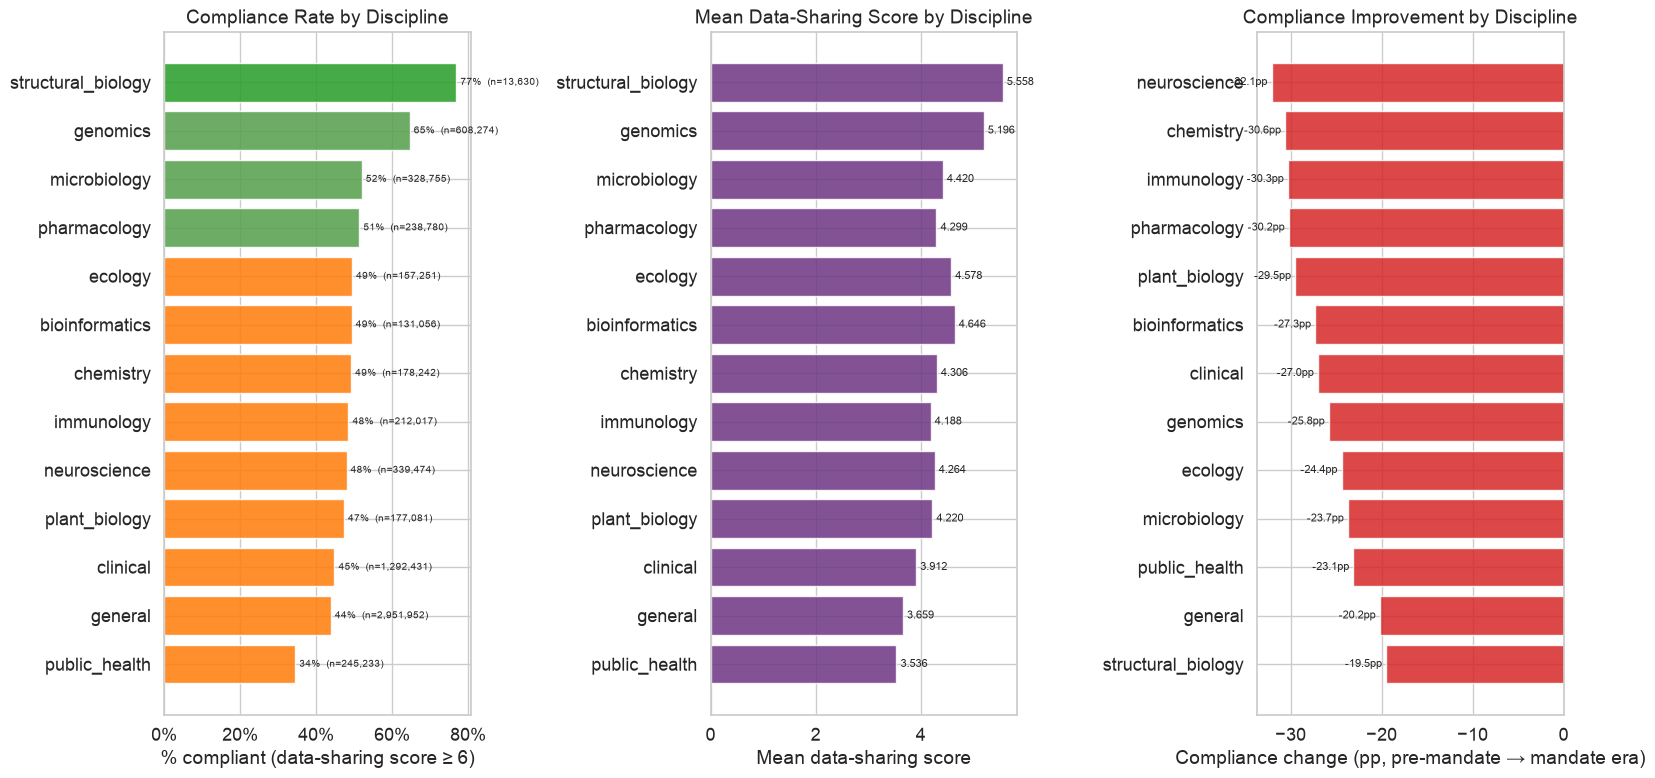

        discipline       n  pct_comply  mean_fair  pct_restrictive  pct_full
structural_biology   13630        76.9        5.6              7.8      17.4
          genomics  608274        64.6        5.2             12.7      20.5
      microbiology  328755        52.0        4.4             20.6      11.5
      pharmacology  238780        51.3        4.3             20.8       5.7
           ecology  157251        49.4        4.6             17.5      14.0
    bioinformatics  131056        49.3        4.6             16.3      16.1
         chemistry  178242        49.2        4.3             20.1       6.4
        immunology  212017        48.5        4.2             22.3       5.7
      neuroscience  339474        48.0        4.3             22.5       9.3
     plant_biology  177081        47.3        4.2             21.9       7.3
          clinical 1292431        44.8        3.9             25.6       3.4
           general 2951952        43.8        3.7             32.2       4.0

In [12]:
if not HAS_DISC:
    print('Skipped — discipline data not available in this database.')
else:
    if 'df_disc' not in dir():
        df_disc = qdb("""SELECT a.article_id, ad.discipline, a.year AS year
                      FROM article a JOIN article_discipline ad ON ad.article_id = a.article_id
                      WHERE a.year BETWEEN 2011 AND 2025""")
        df_disc = df_disc.merge(df[['article_id','data_sharing_score','is_compliant',
                                    'das_cat','era']], on='article_id', how='left')

    disc_agg = (df_disc.groupby('discipline').agg(
        n           = ('article_id','count'),
        pct_comply  = ('is_compliant', lambda x: x.mean()*100),
        mean_fair   = ('data_sharing_score','mean'),
        pct_restrictive    = ('data_sharing_score', lambda x: (x<=1).mean()*100),
        pct_full    = ('data_sharing_score', lambda x: (x>=8).mean()*100),
    ).reset_index().sort_values('pct_comply', ascending=False))

    # Pre/post data-sharing compliance by discipline
    disc_pp = (df_disc.groupby(['discipline','era']).agg(
        pct_comply = ('is_compliant', lambda x: x.mean()*100),
        n          = ('article_id','count'),
    ).unstack().round(1))
    disc_pp.columns = ['_'.join(c) for c in disc_pp.columns]

    fig, axes = plt.subplots(1, 3, figsize=(FIG_W + 2, FIG_H + 3))

    ax = axes[0]
    clrs_d = [C_FULL if r>=70 else (C_COMPLY if r>=50 else
              (C_PARTIAL if r>=30 else C_NON))
              for r in disc_agg['pct_comply'][::-1]]
    bars = ax.barh(disc_agg['discipline'][::-1], disc_agg['pct_comply'][::-1],
                   color=clrs_d, alpha=0.88, edgecolor='white')
    ax.bar_label(bars, labels=[f'{r:.0f}%  (n={int(n):,})'
                 for r, n in zip(disc_agg['pct_comply'][::-1],
                                 disc_agg['n'][::-1])],
                 padding=3, fontsize=7.5)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(xmax=100))
    ax.set_xlabel('% compliant (data-sharing score ≥ 6)')
    ax.set_title('Compliance Rate by Discipline')

    ax = axes[1]
    bars2 = ax.barh(disc_agg['discipline'][::-1], disc_agg['mean_fair'][::-1],
                    color='#6c3483', alpha=0.85, edgecolor='white')
    ax.bar_label(bars2, fmt='{:.3f}', padding=3, fontsize=8)
    ax.set_xlabel('Mean data-sharing score')
    ax.set_title('Mean Data-Sharing Score by Discipline')

    ax = axes[2]
    # Change in compliance pre→post FAIR era
    pre_col  = [c for c in disc_pp.columns if 'Pre' in c and 'comply' in c]
    post_col = [c for c in disc_pp.columns if 'Mandate' in c and 'comply' in c]
    if pre_col and post_col:
        delta_disc = (disc_pp[post_col[0]] - disc_pp[pre_col[0]]).dropna().sort_values()
        clrs_dd = [C_FULL if d>=20 else (C_COMPLY if d>=5 else
                   (C_NON if d<0 else C_PARTIAL))
                   for d in delta_disc[::-1]]
        bars3 = ax.barh(delta_disc.index[::-1], delta_disc.values[::-1],
                        color=clrs_dd, alpha=0.85, edgecolor='white')
        ax.bar_label(bars3, fmt='{:+.1f}pp', padding=3, fontsize=8)
        ax.axvline(0, color='black', lw=0.8)
        ax.set_xlabel('Compliance change (pp, pre-mandate → mandate era)')
        ax.set_title('Compliance Improvement by Discipline')

    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "fig_mandate_09_discipline.png", **SAVEFIG_KWARGS)
    plt.show()
    print(disc_agg.round(1).to_string(index=False))


---
## §10 — Open Access Status × Mandate Compliance

Diamond/gold OA journals often mandate data availability as part of their
open-science ethos. Subscription journals may have weaker enforcement.
We test whether OA status predicts compliance above and beyond the data-sharing score.

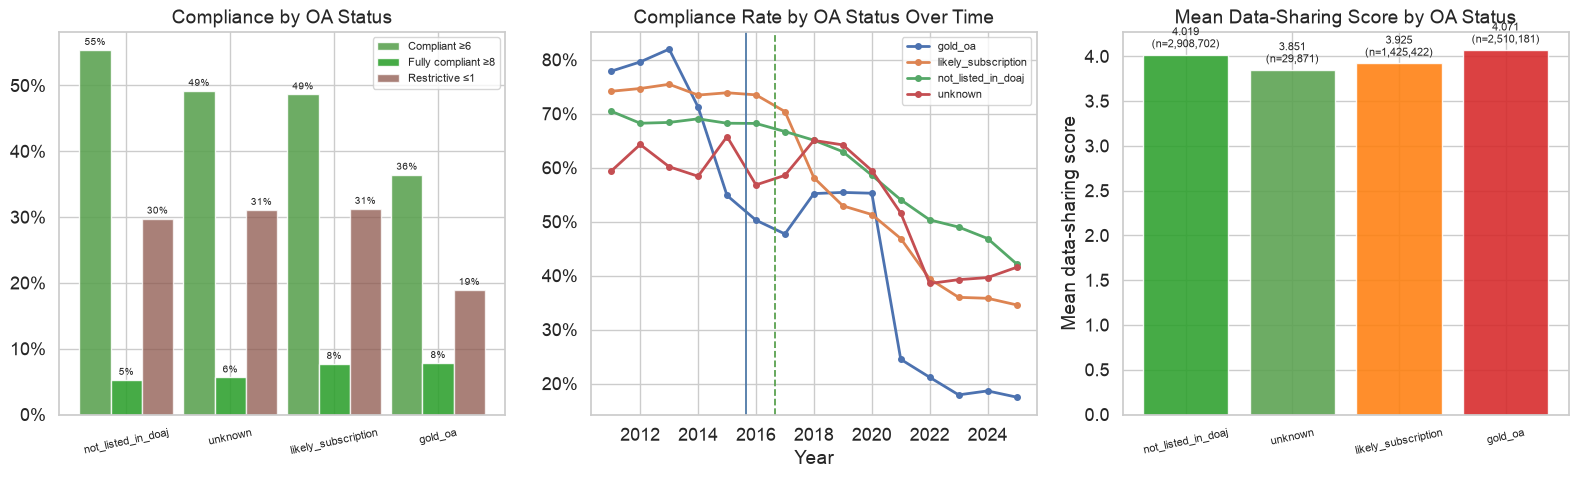

          oa_status       n  pct_comply  pct_full  pct_restrictive  mean_fair
 not_listed_in_doaj 2908702        55.4       5.3             29.8        4.0
            unknown   29871        49.2       5.6             31.1        3.9
likely_subscription 1425422        48.7       7.7             31.3        3.9
            gold_oa 2510181        36.4       7.8             18.9        4.1


In [13]:
if not HAS_OA:
    print('Skipped — OA status data not available in this database.')
else:
    oa_agg = (df.groupby('oa_status').agg(
        n           = ('article_id','count'),
        pct_comply  = ('is_compliant', lambda x: x.mean()*100),
        pct_full    = ('data_sharing_score', lambda x: (x>=8).mean()*100),
        pct_restrictive    = ('data_sharing_score', lambda x: (x<=1).mean()*100),
        mean_fair   = ('data_sharing_score','mean'),
    ).reset_index().sort_values('pct_comply', ascending=False))

    yr_oa_comply = (df.groupby(['year','oa_status'])['is_compliant']
                    .mean().unstack() * 100)

    fig, axes = plt.subplots(1, 3, figsize=(FIG_W + 2, FIG_H))

    ax = axes[0]
    x = np.arange(len(oa_agg)); w = 0.30
    b1 = ax.bar(x - w,   oa_agg['pct_comply'], width=w, color=C_COMPLY, alpha=0.88,
                label='Compliant ≥6', edgecolor='white')
    b2 = ax.bar(x,       oa_agg['pct_full'],   width=w, color=C_FULL,   alpha=0.88,
                label='Fully compliant ≥8', edgecolor='white')
    b3 = ax.bar(x + w,   oa_agg['pct_restrictive'],   width=w, color=C_REST,   alpha=0.75,
                label='Restrictive ≤1', edgecolor='white')
    ax.bar_label(b1, fmt='{:.0f}%', padding=2, fontsize=7.5)
    ax.bar_label(b2, fmt='{:.0f}%', padding=2, fontsize=7.5)
    ax.bar_label(b3, fmt='{:.0f}%', padding=2, fontsize=7.5)
    ax.set_xticks(x)
    ax.set_xticklabels(oa_agg['oa_status'], rotation=12, fontsize=8)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter())
    ax.set_title('Compliance by OA Status')
    ax.legend(fontsize=8)

    ax = axes[1]
    for col in yr_oa_comply.columns:
        ax.plot(yr_oa_comply.index, yr_oa_comply[col], lw=2, marker='o', ms=4, label=col)
    for x2, c, ls, _ in MANDATE_LINES[:2]:
        ax.axvline(x2, color=c, lw=1.3, ls=ls)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter())
    ax.set_title('Compliance Rate by OA Status Over Time')
    ax.set_xlabel('Year'); ax.legend(fontsize=8)

    ax = axes[2]
    bars_oa = ax.bar(oa_agg['oa_status'], oa_agg['mean_fair'],
                     color=[C_FULL, C_COMPLY, C_PARTIAL, C_NON][:len(oa_agg)],
                     alpha=0.88, edgecolor='white')
    ax.bar_label(bars_oa, labels=[f'{m:.3f}\n(n={int(n):,})'
                 for m, n in zip(oa_agg['mean_fair'], oa_agg['n'])],
                 padding=3, fontsize=8)
    ax.set_ylabel('Mean data-sharing score')
    ax.set_title('Mean Data-Sharing Score by OA Status')
    ax.set_xticklabels(oa_agg['oa_status'], rotation=12, fontsize=8)

    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "fig_mandate_10_oa.png", **SAVEFIG_KWARGS)
    plt.show()
    print(oa_agg[['oa_status','n','pct_comply','pct_full','pct_restrictive','mean_fair']]
          .round(1).to_string(index=False))


---
## §11 — Repository Choice: Are Authors Picking High-Infrastructure-Tier Hosts?

Even when authors share data, they may choose ephemeral repositories (GitHub,
personal websites) instead of persistent-DOI platforms (Zenodo, Dryad, OSF).
Mandate compliance requires not just sharing but sharing in a *findable* location.
We measure the share of DAS links pointing to persistent vs ephemeral hosts,
and track whether authors are upgrading their repository choices over time.

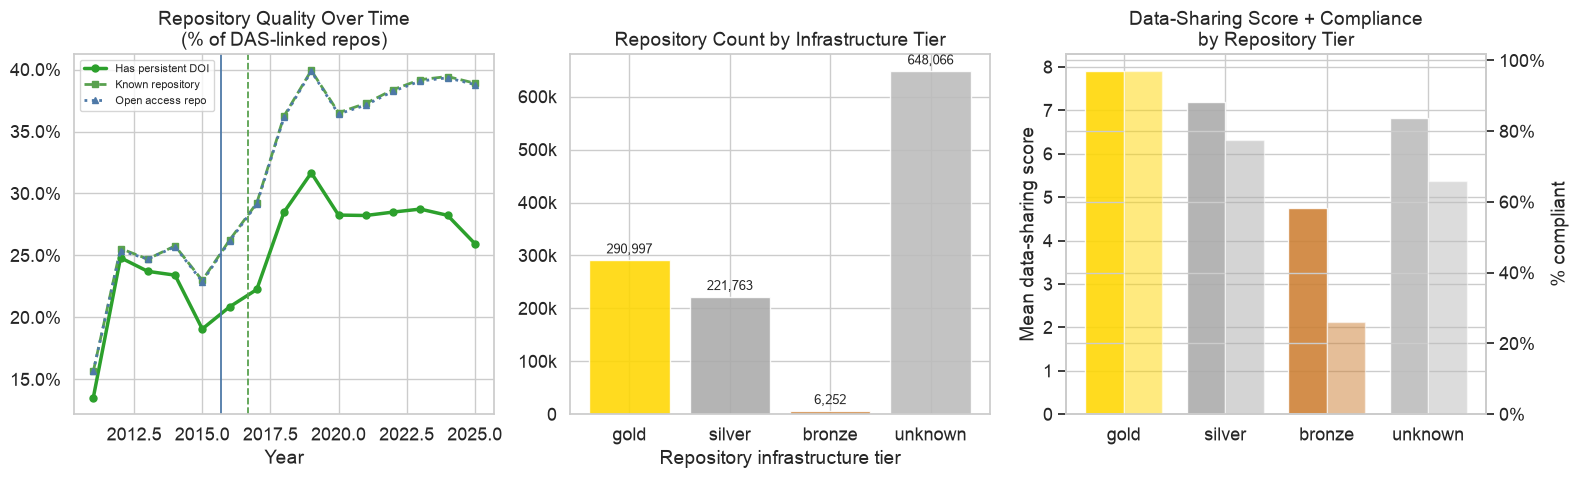

repo_infra_tier      n  mean_fair  pct_comply
           gold 290997        7.9        97.0
         silver 221763        7.2        77.6
         bronze   6252        4.7        26.0
        unknown 648066        6.8        66.0


In [14]:
if not HAS_RC:
    print('Skipped — run classify_repositories.py (Stage 3) first.')
else:
    df_rc = qdb("""
        SELECT da.article_id,
               rc.repo_type, rc.repo_infra_tier, rc.repo_name,
               rc.has_persistent_id, rc.is_known_repo, rc.is_open_access,
               a.year AS year
        FROM data_availability da
        JOIN da_link dl ON dl.da_id = da.da_id
        JOIN repo_classification rc ON rc.link_id = dl.link_id
        JOIN article a ON a.article_id = da.article_id
        WHERE a.year BETWEEN 2011 AND 2025
    """)
    df_rc = df_rc.merge(df[['article_id','data_sharing_score','is_compliant']],
                        on='article_id', how='left')

    # Persistent DOI share over time
    rc_yr = (df_rc.groupby('year').agg(
        pct_persistent = ('has_persistent_id', lambda x: x.mean()*100),
        pct_known      = ('is_known_repo',     lambda x: x.mean()*100),
        pct_oa         = ('is_open_access',    lambda x: x.mean()*100),
        n              = ('article_id','count'),
    ).reset_index())

    # Repository infrastructure tier distribution
    tier_vc = df_rc['repo_infra_tier'].value_counts()
    TIER_ORDER = ['gold','silver','bronze','unknown']
    TIER_CLRS  = ['#ffd700','#aaaaaa','#cd7f32','#bbbbbb']
    tier_agg = (df_rc.groupby('repo_infra_tier').agg(
        n          = ('article_id','count'),
        mean_fair  = ('data_sharing_score','mean'),
        pct_comply = ('is_compliant', lambda x: x.mean()*100),
    ).reindex(TIER_ORDER).dropna().reset_index())

    fig, axes = plt.subplots(1, 3, figsize=(FIG_W + 2, FIG_H))

    ax = axes[0]
    ax.plot(rc_yr['year'], rc_yr['pct_persistent'], lw=2.5, marker='o', ms=5,
            color=C_FULL, label='Has persistent DOI')
    ax.plot(rc_yr['year'], rc_yr['pct_known'], lw=2.0, marker='s', ms=4,
            color=C_COMPLY, ls='--', label='Known repository')
    ax.plot(rc_yr['year'], rc_yr['pct_oa'], lw=2.0, marker='^', ms=4,
            color=C_PRE, ls=':', label='Open access repo')
    for x, c, ls, _ in MANDATE_LINES[:2]:
        ax.axvline(x, color=c, lw=1.3, ls=ls)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter())
    ax.set_title('Repository Quality Over Time\n(% of DAS-linked repos)')
    ax.set_xlabel('Year'); ax.legend(fontsize=8)

    ax = axes[1]
    bars = ax.bar(tier_agg['repo_infra_tier'], tier_agg['n'],
                  color=[TIER_CLRS[TIER_ORDER.index(t)] for t in tier_agg['repo_infra_tier']],
                  alpha=0.88, edgecolor='white')
    ax.bar_label(bars, labels=[f'{int(n):,}' for n in tier_agg['n']],
                 padding=3, fontsize=9)
    ax.yaxis.set_major_formatter(
        mtick.FuncFormatter(lambda v,_: f'{v/1000:.0f}k' if v>=1000 else str(int(v))))
    ax.set_xlabel('Repository infrastructure tier')
    ax.set_title('Repository Count by Infrastructure Tier')

    ax = axes[2]
    x_t = np.arange(len(tier_agg)); w = 0.38
    b1 = ax.bar(x_t - w/2, tier_agg['mean_fair'], width=w,
                color=[TIER_CLRS[TIER_ORDER.index(t)] for t in tier_agg['repo_infra_tier']],
                alpha=0.88, edgecolor='white', label='Mean data-sharing score')
    ax2r = ax.twinx()
    b2 = ax2r.bar(x_t + w/2, tier_agg['pct_comply'], width=w,
                  color=[TIER_CLRS[TIER_ORDER.index(t)] for t in tier_agg['repo_infra_tier']],
                  alpha=0.50, edgecolor='white', label='% compliant')
    ax.set_xticks(x_t); ax.set_xticklabels(tier_agg['repo_infra_tier'])
    ax.set_ylabel('Mean data-sharing score')
    ax2r.set_ylabel('% compliant')
    ax2r.yaxis.set_major_formatter(mtick.PercentFormatter())
    ax.set_title('Data-Sharing Score + Compliance\nby Repository Tier')

    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "fig_mandate_11_repo.png", **SAVEFIG_KWARGS)
    plt.show()
    print(tier_agg[['repo_infra_tier','n','mean_fair','pct_comply']].round(1).to_string(index=False))


---
## §12 — Compliance Gap Heatmap: Funder × Discipline

Where are compliance deficits most severe? This heatmap shows the mean data-sharing
score for every funder × discipline combination with sufficient data,
revealing which funding agencies have the worst compliance in which fields.

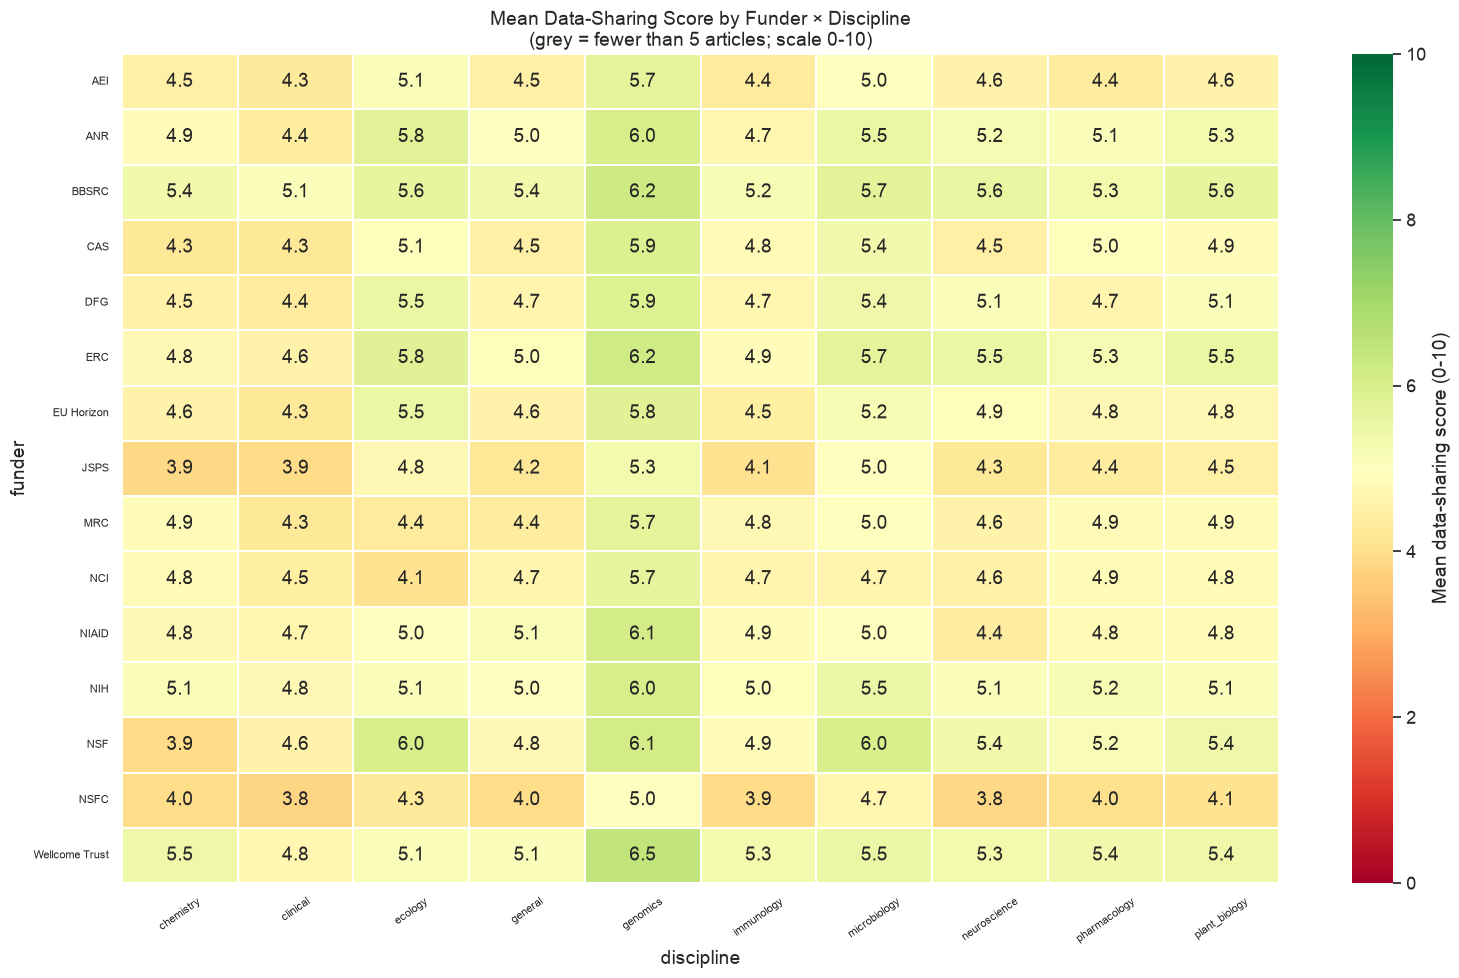

In [15]:
if not (HAS_FUNDER and HAS_DISC):
    print('Skipped — requires article_funder AND article_discipline (Stage 6).')
else:
    # df_af already has data_sharing_score/is_compliant from its earlier merge
    df_fd = df_af.merge(df_disc[['article_id','discipline']], on='article_id', how='inner')

    piv = (df_fd.groupby(['funder','discipline'])
           .agg(mean_fair=('data_sharing_score','mean'), n=('article_id','count'))
           .reset_index())
    # Keep funders and disciplines with sufficient coverage
    top_funders = (piv.groupby('funder')['n'].sum()
                   .nlargest(15).index.tolist())
    top_discs   = (piv.groupby('discipline')['n'].sum()
                   .nlargest(10).index.tolist())
    piv_f = piv[piv['funder'].isin(top_funders) & piv['discipline'].isin(top_discs)]
    hm = piv_f.pivot_table(index='funder', columns='discipline',
                             values='mean_fair', aggfunc='mean')
    hm_n = piv_f.pivot_table(index='funder', columns='discipline',
                               values='n', aggfunc='sum')

    fig, ax = plt.subplots(figsize=(FIG_W + 2, FIG_H + 5))
    mask = hm_n.fillna(0) < 5   # mask cells with too few observations
    sns.heatmap(hm, annot=True, fmt='.1f', cmap='RdYlGn',
                vmin=0, vmax=10, ax=ax, mask=mask,
                linewidths=0.3, cbar_kws={'label': 'Mean data-sharing score (0-10)'})
    ax.set_title('Mean Data-Sharing Score by Funder × Discipline\n'
                 '(grey = fewer than 5 articles; scale 0-10)')
    ax.tick_params(axis='x', rotation=35, labelsize=8)
    ax.tick_params(axis='y', rotation=0,  labelsize=8)

    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "fig_mandate_12_heatmap.png", **SAVEFIG_KWARGS)
    plt.show()


---
## §13 — Country-Level Compliance and Mandate Geography

Funders from different countries have different mandate timelines and
enforcement strengths. We aggregate compliance by the *funder country* —
a proxy for the regulatory environment the researchers operate in.

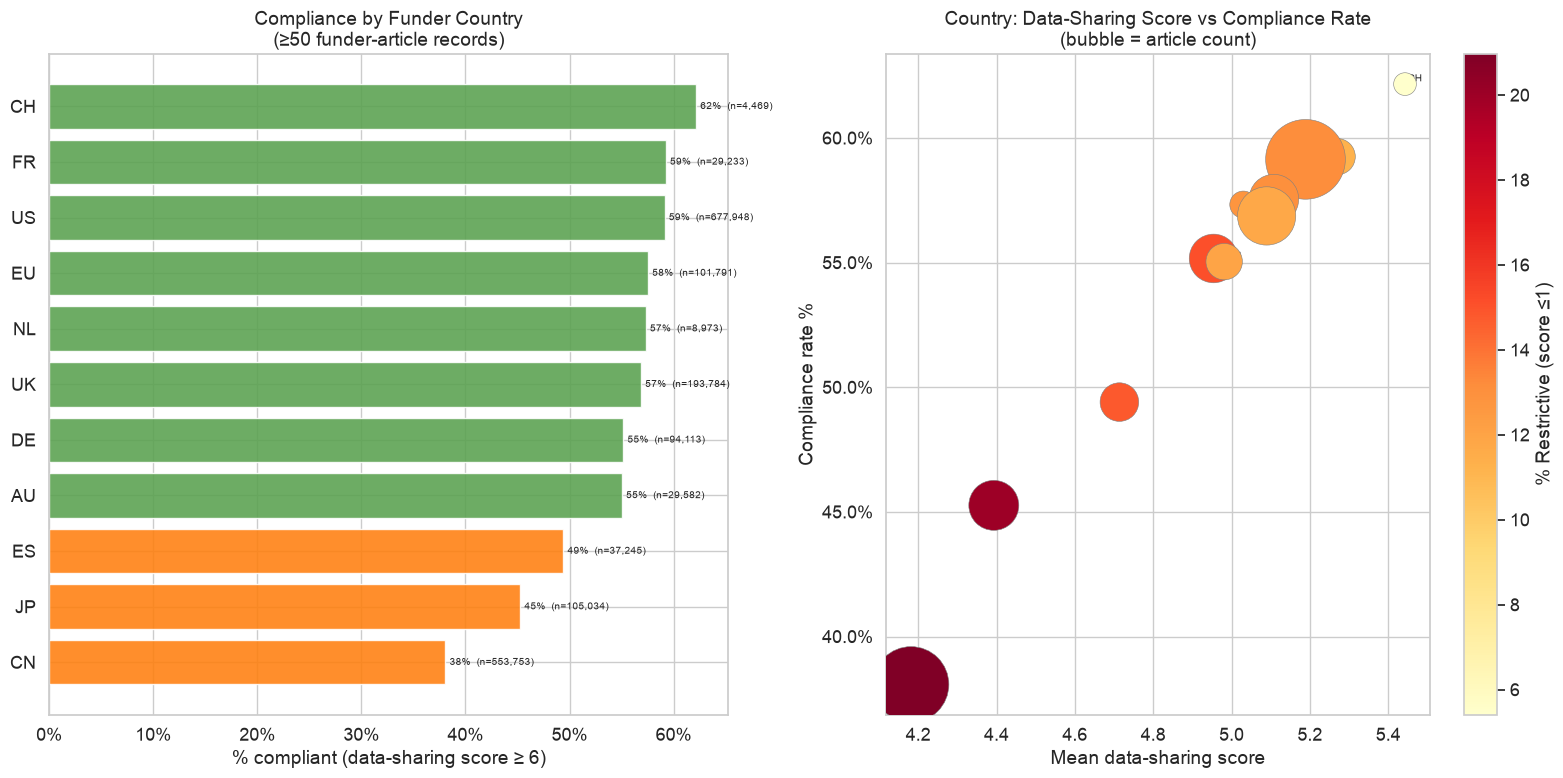

country      n  pct_comply  mean_fair  pct_restrictive
     CH   4469        62.2        5.4              5.4
     FR  29233        59.3        5.3             11.3
     US 677948        59.1        5.2             13.2
     EU 101791        57.5        5.1             13.0
     NL   8973        57.3        5.0             12.8
     UK 193784        56.9        5.1             11.7
     DE  94113        55.2        5.0             15.1
     AU  29582        55.0        5.0             12.0
     ES  37245        49.4        4.7             14.8
     JP 105034        45.3        4.4             20.0
     CN 553753        38.1        4.2             21.0


In [16]:
if not HAS_FUNDER:
    print('Skipped — no funder data.')
else:
    # df_af already has data_sharing_score/is_compliant from its earlier merge
    country_agg = (df_af
        .groupby('country').agg(
            n           = ('article_id','count'),
            pct_comply  = ('is_compliant', lambda x: x.mean()*100),
            mean_fair   = ('data_sharing_score','mean'),
            pct_restrictive    = ('data_sharing_score', lambda x: (x<=1).mean()*100),
        ).reset_index())
    cty = country_agg[country_agg['n'] >= 50].sort_values('pct_comply', ascending=False)
    cty = cty[cty['country'].notna() & (cty['country'] != 'none')]
    cty = cty.nlargest(20, 'pct_comply')  # cap: high-cardinality key (country)

    fig, axes = plt.subplots(1, 2, figsize=(FIG_W + 2, FIG_H + 3))

    ax = axes[0]
    clrs_c = [C_FULL if r>=70 else (C_COMPLY if r>=50 else
              (C_PARTIAL if r>=30 else C_NON))
              for r in cty['pct_comply'][::-1]]
    bars = ax.barh(cty['country'][::-1], cty['pct_comply'][::-1],
                   color=clrs_c, alpha=0.88, edgecolor='white')
    ax.bar_label(bars, labels=[f'{r:.0f}%  (n={int(n):,})'
                 for r, n in zip(cty['pct_comply'][::-1], cty['n'][::-1])],
                 padding=3, fontsize=7.5)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(xmax=100))
    ax.set_xlabel('% compliant (data-sharing score ≥ 6)')
    ax.set_title('Compliance by Funder Country\n(≥50 funder-article records)')

    ax = axes[1]
    sc = ax.scatter(cty['mean_fair'], cty['pct_comply'],
                    s=np.sqrt(cty['n'])*4,
                    c=cty['pct_restrictive'], cmap='YlOrRd',
                    edgecolors='grey', lw=0.4, zorder=5)
    plt.colorbar(sc, ax=ax, label='% Restrictive (score ≤1)')
    for _, row in cty.iterrows():
        ax.annotate(str(row['country']),
                    (row['mean_fair'], row['pct_comply']),
                    fontsize=7.5, xytext=(2,2), textcoords='offset points')
    ax.set_xlabel('Mean data-sharing score')
    ax.yaxis.set_major_formatter(mtick.PercentFormatter())
    ax.set_ylabel('Compliance rate %')
    ax.set_title('Country: Data-Sharing Score vs Compliance Rate\n(bubble = article count)')

    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "fig_mandate_13_country.png", **SAVEFIG_KWARGS)
    plt.show()
    print(cty.round(1).to_string(index=False))


---
## §14 — DAS Completeness: Does the Statement Meet What Mandates Specify?

A mandate-compatible DAS typically requires:
1. A **named repository** (not just 'data available')
2. A **persistent identifier** (DOI or accession number)
3. A **license statement** (CC0, CC-BY, or explicit terms)
4. An **access condition** (open, embargo, or restricted with reason)

We score each DAS against these four criteria and build a 0-4 completeness
score, then track it over time and by funder.

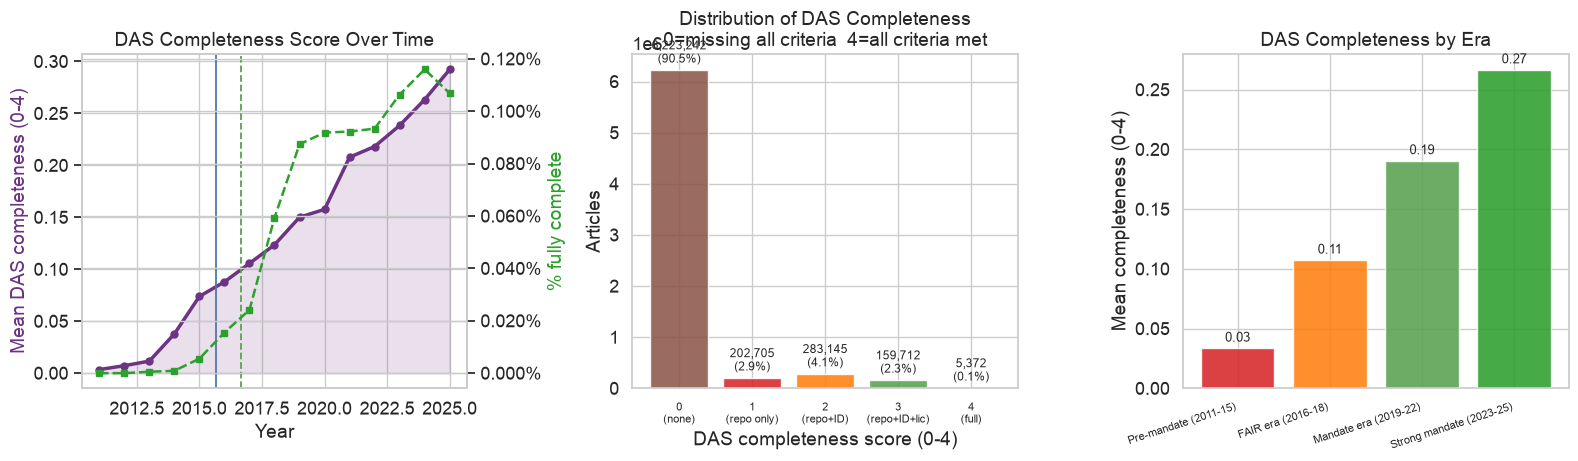

Mean completeness by era:


                           mean    std    count
era                                            
Pre-mandate (2011-15)     0.033  0.276   922067
FAIR era (2016-18)        0.107  0.479   945117
Mandate era (2019-22)     0.190  0.629  2573853
Strong mandate (2023-25)  0.266  0.724  2433139


In [17]:
# Build completeness score (0-4):
# 1 = has named repository (das_cat = repository_named or accession_provided)
# 2 = has persistent ID (doi mention or has_accession)
# 3 = has license mention
# 4 = has_url (data is actually accessible, not just described)
df['completeness'] = (
    df['das_cat'].isin(['repository_named','accession_provided']).astype(int) +
    (df['mentions_doi'] | df['has_accession']).astype(int) +
    df['mentions_license'].astype(int) +
    df['has_url'].astype(int)
)

comp_yr = df.groupby('year').agg(
    mean_completeness = ('completeness','mean'),
    pct_complete4     = ('completeness', lambda x: (x==4).mean()*100),
    pct_complete3plus = ('completeness', lambda x: (x>=3).mean()*100),
    pct_zero          = ('completeness', lambda x: (x==0).mean()*100),
).reset_index()
comp_yr = comp_yr[comp_yr['year'].between(2011, 2025)]

fig, axes = plt.subplots(1, 3, figsize=(FIG_W + 2, FIG_H))

ax = axes[0]
ax.fill_between(comp_yr['year'], comp_yr['mean_completeness'],
                alpha=0.15, color='#6c3483')
ax.plot(comp_yr['year'], comp_yr['mean_completeness'], lw=2.5, marker='o', ms=5,
        color='#6c3483', label='Mean completeness (0-4)')
ax2r = ax.twinx()
ax2r.plot(comp_yr['year'], comp_yr['pct_complete4'], lw=1.8, marker='s', ms=4,
          color=C_FULL, ls='--', label='% fully complete (4/4)')
for x, c, ls, _ in MANDATE_LINES[:2]:
    ax.axvline(x, color=c, lw=1.3, ls=ls)
ax.set_ylabel('Mean DAS completeness (0-4)', color='#6c3483')
ax2r.set_ylabel('% fully complete', color=C_FULL)
ax2r.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title('DAS Completeness Score Over Time')
ax.set_xlabel('Year')

ax = axes[1]
comp_dist = df['completeness'].value_counts().sort_index()
clrs_comp = [C_REST, C_NON, C_PARTIAL, C_COMPLY, C_FULL]
bars = ax.bar(comp_dist.index, comp_dist.values,
              color=clrs_comp[:len(comp_dist)], alpha=0.88, edgecolor='white')
ax.bar_label(bars, labels=[f'{int(v):,}\n({v/len(df)*100:.1f}%)'
             for v in comp_dist.values], padding=3, fontsize=8.5)
ax.set_xlabel('DAS completeness score (0-4)')
ax.set_ylabel('Articles')
ax.set_title('Distribution of DAS Completeness\n0=missing all criteria  4=all criteria met')
ax.set_xticks([0,1,2,3,4])
ax.set_xticklabels(['0\n(none)','1\n(repo only)','2\n(repo+ID)',
                     '3\n(repo+ID+lic)','4\n(full)'], fontsize=8)

ax = axes[2]
# Completeness by era
era_comp = (df.groupby('era')['completeness']
            .mean().reindex(ERA_ORDER))
bars2 = ax.bar(range(len(ERA_ORDER)), era_comp.values,
               color=[C_NON, C_PARTIAL, C_COMPLY, C_FULL], alpha=0.88, edgecolor='white')
ax.bar_label(bars2, fmt='{:.2f}', padding=3, fontsize=9)
ax.set_xticks(range(len(ERA_ORDER)))
ax.set_xticklabels(ERA_ORDER, rotation=18, ha='right', fontsize=8)
ax.set_ylabel('Mean completeness (0-4)')
ax.set_title('DAS Completeness by Era')

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_mandate_14_completeness.png", **SAVEFIG_KWARGS)
plt.show()
print('Mean completeness by era:')
print(df.groupby('era')['completeness'].agg(['mean','std','count'])
        .reindex(ERA_ORDER).round(3).to_string())


---
## §15 — Statistical Summary + Compliance Scorecard + Exports

In [18]:
print('=' * 72)
print('MANDATE COMPATIBILITY ANALYSIS  —  SUMMARY')
print('=' * 72)

n = len(df)
for lbl, val in [
        ('Total articles 2011-2025',               f'{n:,}'),
        ('',                                        ''),
        ('Fully compliant  (score 8-10)',            f'{(df["data_sharing_score"]>=8).sum():>8,}  ({(df["data_sharing_score"]>=8).mean()*100:.1f}%)'),
        ('Compliant        (score 6-7)',             f'{df["data_sharing_score"].between(6,7).sum():>8,}  ({df["data_sharing_score"].between(6,7).mean()*100:.1f}%)'),
        ('Partial          (score 4-5)',             f'{df["data_sharing_score"].between(4,5).sum():>8,}  ({df["data_sharing_score"].between(4,5).mean()*100:.1f}%)'),
        ('Non-compliant    (score 2-3)',             f'{df["data_sharing_score"].between(2,3).sum():>8,}  ({df["data_sharing_score"].between(2,3).mean()*100:.1f}%)'),
        ('Restrictive        (score 0-1)',             f'{(df["data_sharing_score"]<=1).sum():>8,}  ({(df["data_sharing_score"]<=1).mean()*100:.1f}%)'),
        ('',                                        ''),
        ('Overall compliance rate (≥6)',            f'{df["is_compliant"].mean()*100:.1f}%'),
        ('Available-on-request articles',           f'{(df["das_cat"]=="available_on_request").sum():,}  ({(df["das_cat"]=="available_on_request").mean()*100:.1f}%)'),
        ('Mean DAS completeness score (0-4)',       f'{df["completeness"].mean():.3f}'),
        ('',                                        ''),
]:
    print(f'  {lbl:46} {val}')

# Era compliance table
print('\nCompliance rate by era:')
era_comply = df.groupby('era').agg(
    n=('article_id','count'),
    pct_comply=('is_compliant', lambda x: x.mean()*100),
    mean_fair =('data_sharing_score','mean'),
    pct_restrictive  =('data_sharing_score', lambda x: (x<=1).mean()*100),
).reindex(ERA_ORDER)
print(era_comply.round(1).to_string())


MANDATE COMPATIBILITY ANALYSIS  —  SUMMARY


  Total articles 2011-2025                       6,874,176
                                                 
  Fully compliant  (score 8-10)                   461,028  (6.7%)
  Compliant        (score 6-7)                   2,773,449  (40.3%)
  Partial          (score 4-5)                   1,056,764  (15.4%)
  Non-compliant    (score 2-3)                    786,906  (11.4%)
  Restrictive        (score 0-1)                 1,796,029  (26.1%)
                                                 
  Overall compliance rate (≥6)                   47.1%
  Available-on-request articles                  824,949  (12.0%)
  Mean DAS completeness score (0-4)              0.185
                                                 

Compliance rate by era:


                                n  pct_comply  mean_fair  pct_restrictive
era                                                                      
Pre-mandate (2011-15)      922067        71.0        4.5             22.1
FAIR era (2016-18)         945117        61.8        4.4             21.8
Mandate era (2019-22)     2573853        45.8        4.0             26.4
Strong mandate (2023-25)  2433139        33.6        3.7             29.1


In [19]:
export_dir = Path('../results/fair_mandate_exports')
export_dir.mkdir(parents=True, exist_ok=True)

base_cols = ['article_id','year','era','journal_id','journal_title','publisher',
             'data_sharing_score','comply_tier','is_compliant','das_cat','completeness',
             'has_das','das_tier','mentions_license','mentions_doi',
             'has_accession','has_url','das_words']
if HAS_OA: base_cols.append('oa_status')

exports = {
    'article_compliance.csv': df[base_cols],
    'compliance_by_year.csv': yr if 'yr' in dir() else pd.DataFrame(),
    'journal_compliance.csv': j_agg if 'j_agg' in dir() else pd.DataFrame(),
    'publisher_compliance.csv': pub_agg if 'pub_agg' in dir() else pd.DataFrame(),
    'completeness_by_year.csv': comp_yr,
    'era_compliance.csv': era_comply.reset_index(),
}
if HAS_FUNDER:
    exports['funder_compliance.csv']   = f_agg_50 if 'f_agg_50' in dir() else pd.DataFrame()
    exports['mandate_delta.csv']       = df_mandate if 'df_mandate' in dir() else pd.DataFrame()
    exports['funder_year_trend.csv']   = f_yr2 if 'f_yr2' in dir() else pd.DataFrame()
    exports['country_compliance.csv']  = cty if 'cty' in dir() else pd.DataFrame()
if HAS_DISC:
    exports['discipline_compliance.csv'] = disc_agg if 'disc_agg' in dir() else pd.DataFrame()

for fname, df_e in exports.items():
    if df_e is None or (hasattr(df_e,'__len__') and len(df_e) == 0):
        print(f'  skipped (empty): {fname}'); continue
    df_e.to_csv(export_dir / fname, index=False)
    print(f'  saved  {fname}  ({len(df_e):,} rows)')

con.close()
print('\nAll done.')


  saved  article_compliance.csv  (6,874,176 rows)
  saved  compliance_by_year.csv  (15 rows)
  saved  journal_compliance.csv  (3,944 rows)
  saved  publisher_compliance.csv  (812 rows)
  saved  completeness_by_year.csv  (15 rows)
  saved  era_compliance.csv  (4 rows)
  saved  funder_compliance.csv  (8,196 rows)
  saved  mandate_delta.csv  (14 rows)


  saved  funder_year_trend.csv  (105,206 rows)
  saved  country_compliance.csv  (11 rows)
  saved  discipline_compliance.csv  (13 rows)

All done.
